# 🔍 Feature Selection & Feature Importance Analysis for APT Attack Detection (V2 - No Leakage + SecBERT)

## Objectives
This notebook performs comprehensive feature analysis for Advanced Persistent Threat (APT) detection:

### 1️⃣ **Malicious vs Benign Classification**
- Identify which features are most important for determining if an alert is **malicious** or **benign**
- Use multiple feature importance methods: Random Forest, XGBoost, Permutation Importance, SHAP values

### 2️⃣ **Cyber Kill Chain Stage Classification**
- Identify which features are most important for determining the **stage/step** of the Cyber Kill Chain
- Understand feature patterns across: Reconnaissance, Weaponization, Delivery, Exploitation, Installation, C2, Actions

### Techniques Used:
- **Filter Methods**: Correlation analysis, Chi-square, Mutual Information
- **Wrapper Methods**: Recursive Feature Elimination (RFE)
- **Embedded Methods**: Random Forest, XGBoost, LightGBM feature importance
- **Model-Agnostic**: Permutation Importance, SHAP values

### ⚠️ Data Leakage Prevention (V2 Improvements)
Following the AE notebook's approach, we now **exclude ALL leaky features**:
- `_source.rule.level` → Severity score = **indirect malicious label**
- `_source.rule.mitre_tactics/techniques` → Only exist for malicious alerts
- `_source.rule.description` → Contains attack keywords = leaky

### 🤖 SecBERT Text Embeddings (NEW)
- Use **SecBERT** (cybersecurity-pretrained BERT) for semantic embeddings of text fields
- Applied to `_source.data.command` and `_source.full_log`
- Captures **semantic meaning** instead of just keyword matching

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder, MultiLabelBinarizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.feature_selection import (
    SelectKBest, chi2, mutual_info_classif, f_classif,
    RFE, RFECV, VarianceThreshold
)
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.inspection import permutation_importance
import warnings
warnings.filterwarnings('ignore')

# Import ML libraries
import xgboost as xgb
print("✅ XGBoost imported successfully")

import lightgbm as lgb
print("✅ LightGBM imported successfully")

import shap
print("✅ SHAP imported successfully")

# Import SecBERT / Transformers
import torch
from transformers import AutoTokenizer, AutoModel
print("✅ Transformers (SecBERT) imported successfully")
print(f"   PyTorch version: {torch.__version__}")
print(f"   CUDA available: {torch.cuda.is_available()}")

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

print("\n✅ All libraries imported successfully!")
print(f"📊 Ready for Feature Selection Analysis (V2 - No Leakage + SecBERT)")

✅ XGBoost imported successfully
✅ LightGBM imported successfully
✅ SHAP imported successfully
✅ Transformers (SecBERT) imported successfully
   PyTorch version: 2.2.1+cu118
   CUDA available: True

✅ All libraries imported successfully!
📊 Ready for Feature Selection Analysis (V2 - No Leakage + SecBERT)


## 📁 Part 1: Load and Explore the Dataset

In [2]:
# Load the dataset
data_path = r"c:\Users\KassoussiOussama-PFE\Downloads\pfe\combined_dataset_final.xlsx"
df = pd.read_excel(data_path)

print(f"📊 Dataset loaded successfully!")
print(f"   Shape: {df.shape}")
print(f"   Rows: {len(df):,}")
print(f"   Columns: {len(df.columns)}")

print("\n" + "="*70)
print("📋 All Columns in Dataset:")
print("="*70)
for i, col in enumerate(df.columns, 1):
    print(f"   {i:2d}. {col}")

print("\n" + "="*70)
print("🎯 TARGET VARIABLES")
print("="*70)

# Check malicious label
print("\n1️⃣ Malicious Label Distribution:")
print(df['malicious'].value_counts())
malicious_pct = (df['malicious'] == 1).mean() * 100
print(f"   → Benign: {(df['malicious'] == 0).sum():,} ({100-malicious_pct:.1f}%)")
print(f"   → Malicious: {(df['malicious'] == 1).sum():,} ({malicious_pct:.1f}%)")

# Check Cyber Kill Chain
print("\n2️⃣ Cyber Kill Chain Tactic Distribution:")
ckc_counts = df['cyber_kill_chain_tactic'].value_counts()
print(ckc_counts)

# Display first few rows
print("\n" + "="*70)
print("📄 Sample Data (first 3 rows):")
print("="*70)
df.head(3)

📊 Dataset loaded successfully!
   Shape: (115726, 176)
   Rows: 115,726
   Columns: 176

📋 All Columns in Dataset:
    1. _index
    2. _id
    3. _version
    4. _score
    5. _source.agent.ip
    6. _source.agent.name
    7. _source.agent.id
    8. _source.manager.name
    9. _source.data.audit.syscall
   10. _source.data.audit.gid
   11. _source.data.audit.fsgid
   12. _source.data.audit.session
   13. _source.data.audit.pid
   14. _source.data.audit.suid
   15. _source.data.audit.type
   16. _source.data.audit.uid
   17. _source.data.audit.egid
   18. _source.data.audit.exe
   19. _source.data.audit.file.inode
   20. _source.data.audit.file.mode
   21. _source.data.audit.file.name
   22. _source.data.audit.sgid
   23. _source.data.audit.id
   24. _source.data.audit.key
   25. _source.data.audit.auid
   26. _source.data.audit.execve.a1
   27. _source.data.audit.execve.a2
   28. _source.data.audit.execve.a3
   29. _source.data.audit.execve.a4
   30. _source.data.audit.execve.a5
   31

,_index,_id,_version,_score,_source.agent.ip,_source.agent.name,_source.agent.id,_source.manager.name,_source.data.audit.syscall,_source.data.audit.gid,_source.data.audit.fsgid,_source.data.audit.session,_source.data.audit.pid,_source.data.audit.suid,_source.data.audit.type,_source.data.audit.uid,_source.data.audit.egid,_source.data.audit.exe,_source.data.audit.file.inode,_source.data.audit.file.mode,_source.data.audit.file.name,_source.data.audit.sgid,_source.data.audit.id,_source.data.audit.key,_source.data.audit.auid,_source.data.audit.execve.a1,_source.data.audit.execve.a2,_source.data.audit.execve.a3,_source.data.audit.execve.a4,_source.data.audit.execve.a5,_source.data.audit.execve.a0,_source.data.audit.euid,_source.data.audit.command,_source.data.audit.ppid,_source.data.audit.fsuid,_source.data.audit.exit,_source.data.audit.cwd,_source.data.audit.success,_source.data.audit.tty,_source.data.audit.arch,_source.rule.firedtimes,_source.rule.mail,_source.rule.level,_source.rule.description,_source.rule.groups,_source.rule.id,_source.rule.gdpr,_source.decoder.parent,_source.decoder.name,_source.full_log,_source.input.type,_source.@timestamp,_source.location,_source.id,_source.timestamp,_source.data.audit.execve.a6,_source.data.audit.execve.a7,_source.data.dpkg_status,_source.data.package,_source.data.arch,_source.data.version,_source.rule.pci_dss,_source.rule.hipaa,_source.rule.tsc,_source.rule.nist_800_53,_source.rule.gpg13,_source.predecoder.hostname,_source.predecoder.program_name,_source.predecoder.timestamp,_source.data.srcuser,_source.data.dstuser,_source.data.tty,_source.data.pwd,_source.data.command,_source.rule.mitre.technique,_source.rule.mitre.id,_source.rule.mitre.tactic,_source.decoder.ftscomment,_source.data.uid,_source.data.audit.res,_source.previous_output,_source.previous_log,_source.data.level,_source.data.sca.scan_id,_source.data.sca.check.result,_source.data.sca.check.remediation,_source.data.sca.check.compliance.pci_dss,_source.data.sca.check.compliance.nist_800_53,_source.data.sca.check.description,_source.data.sca.check.id,_source.data.sca.check.title,_source.data.sca.check.rationale,_source.data.sca.check.command,_source.data.sca.type,_source.data.sca.policy,_source.data.sca.score,_source.data.sca.total_checks,_source.data.sca.file,_source.data.sca.policy_id,_source.data.sca.invalid,_source.data.sca.description,_source.data.sca.passed,_source.data.sca.failed,_source.data.extra_data,_source.data.file,_source.data.title,_source.syscheck.size_before,_source.syscheck.uname_after,_source.syscheck.mtime_after,_source.syscheck.inode_before,_source.syscheck.size_after,_source.syscheck.gid_after,_source.syscheck.md5_before,_source.syscheck.sha256_before,_source.syscheck.mtime_before,_source.syscheck.mode,_source.syscheck.path,_source.syscheck.sha1_after,_source.syscheck.changed_attributes,_source.syscheck.gname_after,_source.syscheck.uid_after,_source.syscheck.perm_after,_source.syscheck.event,_source.syscheck.md5_after,_source.syscheck.sha1_before,_source.syscheck.sha256_after,_source.syscheck.inode_after,_source.data.sca.check.previous_result,_source.data.srcip,_source.data.srcport,malicious,cyber_kill_chain_technique,cyber_kill_chain_id,cyber_kill_chain_tactic,_source.data.audit.list,_source.data.euid,_source.data.gid,_source.data.home,_source.data.id,_source.data.logname,_source.data.protocol,_source.data.sca.check.compliance.cis,_source.data.sca.check.compliance.cis_csc_v7,_source.data.sca.check.compliance.cis_csc_v8,_source.data.sca.check.compliance.cmmc_v2.0,_source.data.sca.check.compliance.hipaa,_source.data.sca.check.compliance.mitre_mitigations,_source.data.sca.check.compliance.mitre_tactics,_source.data.sca.check.compliance.mitre_techniques,_source.data.sca.check.compliance.nist_sp_800-53,_source.data.sca.check.compliance.pci_dss_3.2.1,_source.data.sca.check.compliance.pci_dss_4.0,_source.data.sca.check.compliance.pci_dss_v3.2.1,_source.data.sca.check.compliance.pci_dss_v4.0,_source.data.sca.check.c

## 🤖 Part 2a: SecBERT Text Embedding

Load SecBERT and create embeddings for textual SIEM fields (`_source.data.command`, `_source.full_log`).
SecBERT is a BERT model pre-trained on cybersecurity text, so it understands security-specific semantics.

In [3]:
# ============================================================================
# 🤖 SecBERT Embedding Generator
# ============================================================================

class SecBERTEmbedder:
    """
    Generate text embeddings using SecBERT (cybersecurity-pretrained BERT).
    Uses mean pooling of last hidden states for sentence-level embeddings.
    """
    
    def __init__(self, model_name='jackaduma/SecBERT', n_components=16, batch_size=64):
        """
        Args:
            model_name: HuggingFace model name
            n_components: Number of PCA components to reduce embeddings to
            batch_size: Batch size for inference
        """
        self.n_components = n_components
        self.batch_size = batch_size
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        
        print(f"🤖 Loading SecBERT model: {model_name}")
        print(f"   Device: {self.device}")
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)
        self.model = AutoModel.from_pretrained(model_name).to(self.device)
        self.model.eval()
        print(f"✅ SecBERT loaded! (Hidden size: {self.model.config.hidden_size})")
        
        self.pca = None  # Will be fitted during transform
    
    def _mean_pooling(self, model_output, attention_mask):
        """Mean pooling over token embeddings (ignoring padding)."""
        token_embeddings = model_output.last_hidden_state
        input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
        return torch.sum(token_embeddings * input_mask_expanded, 1) / torch.clamp(
            input_mask_expanded.sum(1), min=1e-9
        )
    
    def embed_texts(self, texts, prefix='secbert'):
        """
        Generate embeddings for a list of texts.
        Returns DataFrame with PCA-reduced embedding columns.
        """
        from sklearn.decomposition import PCA
        
        # Clean texts - replace NaN/empty with placeholder
        clean_texts = []
        for t in texts:
            if pd.isna(t) or str(t).strip() == '':
                clean_texts.append('[EMPTY]')
            else:
                # Truncate very long texts to 512 tokens worth (~2000 chars)
                clean_texts.append(str(t)[:2000])
        
        print(f"   Embedding {len(clean_texts)} texts in batches of {self.batch_size}...")
        
        all_embeddings = []
        n_batches = (len(clean_texts) + self.batch_size - 1) // self.batch_size
        
        with torch.no_grad():
            for i in range(0, len(clean_texts), self.batch_size):
                batch = clean_texts[i:i + self.batch_size]
                batch_num = i // self.batch_size + 1
                
                if batch_num % 20 == 0 or batch_num == 1:
                    print(f"   Batch {batch_num}/{n_batches}...")
                
                encoded = self.tokenizer(
                    batch, 
                    padding=True, 
                    truncation=True, 
                    max_length=128,  # Keep short for speed
                    return_tensors='pt'
                ).to(self.device)
                
                outputs = self.model(**encoded)
                embeddings = self._mean_pooling(outputs, encoded['attention_mask'])
                all_embeddings.append(embeddings.cpu().numpy())
        
        # Concatenate all batches
        full_embeddings = np.vstack(all_embeddings)
        print(f"   Raw embedding shape: {full_embeddings.shape}")
        
        # PCA reduction
        print(f"   Reducing to {self.n_components} dimensions with PCA...")
        self.pca = PCA(n_components=self.n_components, random_state=42)
        reduced = self.pca.fit_transform(full_embeddings)
        
        variance_explained = self.pca.explained_variance_ratio_.sum() * 100
        print(f"   PCA variance explained: {variance_explained:.1f}%")
        
        # Create DataFrame
        columns = [f'{prefix}_emb_{i}' for i in range(self.n_components)]
        return pd.DataFrame(reduced, columns=columns, index=range(len(texts)))


# Initialize SecBERT
secbert = SecBERTEmbedder(n_components=16, batch_size=64)

🤖 Loading SecBERT model: jackaduma/SecBERT
   Device: cuda

✅ SecBERT loaded! (Hidden size: 768)


## 🔧 Part 2b: Feature Engineering (Leakage-Free + SecBERT)

### ⚠️ DATA LEAKAGE PREVENTION - Features EXCLUDED:

| Excluded Feature | Original Column | Reason |
|---|---|---|
| `rule_level` | `_source.rule.level` | Wazuh severity score = **indirect malicious label** |
| `is_high_severity` | `_source.rule.level` | Derived from leaky rule_level |
| `is_critical_severity` | `_source.rule.level` | Derived from leaky rule_level |
| `tactic_*` (14 features) | `_source.rule.mitre_tactics` | MITRE mappings **only exist for malicious** alerts |
| `technique_count` | `_source.rule.mitre_techniques` | Same - only malicious alerts have techniques |
| `has_mitre_tactic` | `_source.rule.mitre_tactics` | Same |
| `has_mitre_technique` | `_source.rule.mitre_techniques` | Same |
| `rule_description` text | `_source.rule.description` | Contains attack keywords like "privilege escalation" |

### ✅ Features KEPT (behavioral signals only):
- **Temporal**: hour, day, weekend, night, business hours
- **Network**: IP type, port, protocol
- **File Integrity**: syscheck events, path features, hash presence, changed attributes
- **Commands**: regex pattern flags + **SecBERT semantic embeddings**
- **Full Log**: **SecBERT semantic embeddings** (captures overall event semantics)
- **Metadata**: decoder, location, firedtimes

In [4]:
import re
from collections import Counter
import ipaddress

class FeatureEngineerNoLeakage:
    """
    Feature engineering for SIEM data - NO DATA LEAKAGE version.
    
    EXCLUDED (leaky features):
    - _source.rule.level         → severity score = indirect label
    - _source.rule.mitre_tactics → only present for malicious alerts
    - _source.rule.mitre_techniques → only present for malicious alerts  
    - _source.rule.description   → contains attack keywords
    
    ADDED:
    - SecBERT embeddings for _source.data.command
    - SecBERT embeddings for _source.full_log
    """
    
    def __init__(self, secbert_embedder=None):
        self.feature_names = []
        self.scaler = StandardScaler()
        self.label_encoders = {}
        self.secbert = secbert_embedder
        
    def _parse_timestamp(self, ts_series):
        """Extract temporal features from timestamps."""
        ts = pd.to_datetime(ts_series, errors='coerce')
        features = pd.DataFrame(index=ts_series.index)
        features['hour_of_day'] = ts.dt.hour.fillna(12).astype(int)
        features['day_of_week'] = ts.dt.dayofweek.fillna(0).astype(int)
        features['is_weekend'] = (features['day_of_week'] >= 5).astype(int)
        features['is_night'] = ((features['hour_of_day'] >= 22) | (features['hour_of_day'] <= 6)).astype(int)
        features['is_business_hours'] = ((features['hour_of_day'] >= 9) & (features['hour_of_day'] <= 17)).astype(int)
        return features
    
    def _is_private_ip(self, ip_str):
        """Check if IP is private."""
        try:
            if pd.isna(ip_str) or ip_str == '':
                return -1
            ip = ipaddress.ip_address(str(ip_str).strip())
            return 1 if ip.is_private else 0
        except:
            return -1
    
    def _extract_path_features(self, path_series):
        """Extract features from file paths."""
        features = pd.DataFrame(index=path_series.index)
        sensitive_dirs = ['/etc', '/var/log', '/home', '/root', '/bin', '/sbin', '/usr/bin', '/tmp', '/var/www']
        suspicious_extensions = ['.sh', '.py', '.php', '.exe', '.bin', '.so', '.conf', '.key', '.pem']
        
        def analyze_path(path):
            if pd.isna(path) or path == '':
                return {'depth': 0, 'is_sensitive': 0, 'is_hidden': 0, 'is_suspicious_ext': 0, 'is_temp': 0}
            path = str(path)
            depth = path.count('/')
            is_sensitive = int(any(d in path for d in sensitive_dirs))
            is_hidden = int('/.' in path)
            is_suspicious_ext = int(any(path.endswith(ext) for ext in suspicious_extensions))
            is_temp = int('/tmp' in path or '/temp' in path)
            return {'depth': min(depth, 15), 'is_sensitive': is_sensitive, 
                    'is_hidden': is_hidden, 'is_suspicious_ext': is_suspicious_ext, 'is_temp': is_temp}
        
        path_feats = path_series.apply(analyze_path).apply(pd.Series)
        for col in path_feats.columns:
            features[f'path_{col}'] = path_feats[col]
        features['path_is_missing'] = path_series.isna().astype(int)
        return features
    
    def _extract_command_features(self, cmd_series):
        """Extract regex-based features from command strings."""
        features = pd.DataFrame(index=cmd_series.index)
        
        suspicious_patterns = {
            'sudo_usage': r'\bsudo\b',
            'chmod_usage': r'\bchmod\b',
            'wget_curl': r'\b(wget|curl)\b',
            'nc_netcat': r'\b(nc|netcat|ncat)\b',
            'base64': r'\bbase64\b',
            'eval_exec': r'\b(eval|exec)\b',
            'pipe_redirect': r'[\|><]',
            'hidden_file': r'\s\.\w+',
            'cron_at': r'\b(cron|crontab|at)\b',
            'ssh_scp': r'\b(ssh|scp|sftp)\b',
            'python_perl': r'\b(python|perl|ruby|php)\b',
            'kill_pkill': r'\b(kill|pkill)\b',
            'rm_delete': r'\brm\b',
            'cat_less': r'\b(cat|less|more|head|tail)\b',
            'grep_find': r'\b(grep|find|locate)\b',
            'env_export': r'\b(env|export)\b',
            'passwd_shadow': r'\b(passwd|shadow)\b',
            'iptables_firewall': r'\biptables\b',
            'dd_disk': r'\bdd\b',
            'tar_zip': r'\b(tar|zip|gzip|bzip2)\b',
        }
        
        for name, pattern in suspicious_patterns.items():
            features[f'cmd_{name}'] = cmd_series.fillna('').apply(
                lambda x: 1 if re.search(pattern, str(x), re.IGNORECASE) else 0
            )
        
        features['cmd_length'] = cmd_series.fillna('').apply(lambda x: len(str(x)))
        features['cmd_has_args'] = cmd_series.fillna('').apply(lambda x: 1 if ' -' in str(x) else 0)
        features['cmd_is_missing'] = cmd_series.isna().astype(int)
        return features
    
    def transform(self, df):
        """Transform the dataframe to feature matrix (NO LEAKAGE)."""
        print("🔄 Starting Feature Engineering (NO DATA LEAKAGE version)...")
        print("   ❌ EXCLUDED: rule_level, is_high/critical_severity, MITRE features, rule description")
        all_features = []
        
        # 1. Timestamp features
        print("  📅 Extracting temporal features...")
        if '_source.@timestamp' in df.columns:
            ts_feats = self._parse_timestamp(df['_source.@timestamp'])
            all_features.append(ts_feats)
            self.feature_names.extend(ts_feats.columns.tolist())
        
        # ❌ REMOVED: rule_level, is_high_severity, is_critical_severity
        # These are LEAKY - severity score is an indirect malicious label
        print("  ⚠️ SKIPPING rule_level features (data leakage!)")
        
        # 2. Rule fired times (kept - this is behavioral, not a label)
        if '_source.rule.firedtimes' in df.columns:
            fired_df = pd.DataFrame(index=df.index)
            fired_df['firedtimes'] = pd.to_numeric(df['_source.rule.firedtimes'], errors='coerce').fillna(0)
            fired_df['firedtimes_log'] = np.log1p(fired_df['firedtimes'])
            all_features.append(fired_df)
            self.feature_names.extend(fired_df.columns.tolist())
        
        # 3. IP features
        print("  🌐 Extracting IP features...")
        ip_cols = ['_source.agent.ip', '_source.data.srcip']
        for col in ip_cols:
            if col in df.columns:
                prefix = col.split('.')[-1]
                ip_df = pd.DataFrame(index=df.index)
                ip_df[f'{prefix}_is_private'] = df[col].apply(self._is_private_ip)
                ip_df[f'{prefix}_is_missing'] = df[col].isna().astype(int)
                all_features.append(ip_df)
                self.feature_names.extend(ip_df.columns.tolist())
        
        # 4. Path features
        print("  📁 Extracting path features...")
        if '_source.syscheck.path' in df.columns:
            path_feats = self._extract_path_features(df['_source.syscheck.path'])
            all_features.append(path_feats)
            self.feature_names.extend(path_feats.columns.tolist())
        
        # 5. Command regex features
        print("  💻 Extracting command pattern features...")
        if '_source.data.command' in df.columns:
            cmd_feats = self._extract_command_features(df['_source.data.command'])
            all_features.append(cmd_feats)
            self.feature_names.extend(cmd_feats.columns.tolist())
        
        # ❌ REMOVED: MITRE features (tactic_*, technique_count, has_mitre_*)
        # These are LEAKY - MITRE mappings only exist for malicious alerts
        print("  ⚠️ SKIPPING MITRE features (data leakage!)")
        
        # 6. Hash presence features
        print("  🔐 Extracting hash features...")
        hash_df = pd.DataFrame(index=df.index)
        if '_source.syscheck.md5_after' in df.columns:
            hash_df['has_md5'] = df['_source.syscheck.md5_after'].notna().astype(int)
        if '_source.syscheck.sha256_after' in df.columns:
            hash_df['has_sha256'] = df['_source.syscheck.sha256_after'].notna().astype(int)
        if len(hash_df.columns) > 0:
            all_features.append(hash_df)
            self.feature_names.extend(hash_df.columns.tolist())
        
        # 7. Syscheck event type
        print("  🔄 Extracting syscheck features...")
        if '_source.syscheck.event' in df.columns:
            syscheck_df = pd.DataFrame(index=df.index)
            for event in ['added', 'modified', 'deleted']:
                syscheck_df[f'syscheck_{event}'] = df['_source.syscheck.event'].fillna('').apply(
                    lambda x: 1 if event in str(x).lower() else 0
                )
            all_features.append(syscheck_df)
            self.feature_names.extend(syscheck_df.columns.tolist())
        
        # 8. Changed attributes
        if '_source.syscheck.changed_attributes' in df.columns:
            attr_df = pd.DataFrame(index=df.index)
            for attr in ['size', 'mtime', 'md5', 'sha1', 'sha256', 'permission', 'uid', 'gid', 'inode']:
                attr_df[f'changed_{attr}'] = df['_source.syscheck.changed_attributes'].fillna('').apply(
                    lambda x: 1 if attr in str(x).lower() else 0
                )
            all_features.append(attr_df)
            self.feature_names.extend(attr_df.columns.tolist())
        
        # 9. Port features
        print("  🔌 Extracting port features...")
        if '_source.data.srcport' in df.columns:
            port_df = pd.DataFrame(index=df.index)
            port_df['srcport'] = pd.to_numeric(df['_source.data.srcport'], errors='coerce').fillna(0)
            port_df['is_privileged_port'] = (port_df['srcport'] < 1024).astype(int)
            port_df['is_high_port'] = (port_df['srcport'] > 49152).astype(int)
            all_features.append(port_df)
            self.feature_names.extend(port_df.columns.tolist())
        
        # 10. Decoder and location (top categories)
        print("  📍 Extracting decoder/location features...")
        cat_cols = {
            '_source.decoder.name': 'decoder',
            '_source.location': 'location'
        }
        for col, prefix in cat_cols.items():
            if col in df.columns:
                top_cats = df[col].value_counts().head(15).index.tolist()
                for cat in top_cats:
                    col_name = f'{prefix}_{str(cat)[:30].replace("/", "_").replace(" ", "_")}'
                    df_temp = pd.DataFrame(index=df.index)
                    df_temp[col_name] = (df[col] == cat).astype(int)
                    all_features.append(df_temp)
                    self.feature_names.append(col_name)
        
        # 11. SecBERT embeddings for text fields
        if self.secbert is not None:
            # Command embeddings
            if '_source.data.command' in df.columns:
                print("  🤖 Generating SecBERT embeddings for commands...")
                cmd_embeddings = self.secbert.embed_texts(
                    df['_source.data.command'].values, prefix='cmd_secbert'
                )
                cmd_embeddings.index = df.index
                all_features.append(cmd_embeddings)
                self.feature_names.extend(cmd_embeddings.columns.tolist())
            
            # Full log embeddings
            if '_source.full_log' in df.columns:
                print("  🤖 Generating SecBERT embeddings for full_log...")
                log_embeddings = self.secbert.embed_texts(
                    df['_source.full_log'].values, prefix='log_secbert'
                )
                log_embeddings.index = df.index
                all_features.append(log_embeddings)
                self.feature_names.extend(log_embeddings.columns.tolist())
        
        # Concatenate all features
        print("  🔗 Concatenating all features...")
        feature_matrix = pd.concat(all_features, axis=1)
        feature_matrix = feature_matrix.fillna(0)
        
        # Remove duplicate columns
        feature_matrix = feature_matrix.loc[:, ~feature_matrix.columns.duplicated()]
        
        print(f"\n✅ Feature Engineering Complete (NO LEAKAGE)!")
        print(f"   Total features created: {feature_matrix.shape[1]}")
        print(f"   Total samples: {feature_matrix.shape[0]:,}")
        print(f"   ❌ Excluded: rule_level, severity flags, MITRE features, rule description")
        print(f"   ✅ Included: SecBERT embeddings for command + full_log")
        
        return feature_matrix

# Initialize and run feature engineering with SecBERT
engineer = FeatureEngineerNoLeakage(secbert_embedder=secbert)
X = engineer.transform(df)

# Get labels
y_malicious = df['malicious'].values
y_ckc = df['cyber_kill_chain_tactic'].fillna('Unknown').values

# Encode CKC labels
ckc_encoder = LabelEncoder()
y_ckc_encoded = ckc_encoder.fit_transform(y_ckc)

print(f"\n📊 Feature Matrix: {X.shape}")
print(f"🎯 Target 1 (Malicious): {len(y_malicious)} samples")
print(f"🎯 Target 2 (CKC): {len(np.unique(y_ckc_encoded))} classes")
print(f"\n🏷️ CKC Classes: {ckc_encoder.classes_}")

🔄 Starting Feature Engineering (NO DATA LEAKAGE version)...
   ❌ EXCLUDED: rule_level, is_high/critical_severity, MITRE features, rule description
  📅 Extracting temporal features...
  ⚠️ SKIPPING rule_level features (data leakage!)
  🌐 Extracting IP features...
  📁 Extracting path features...
  💻 Extracting command pattern features...
  ⚠️ SKIPPING MITRE features (data leakage!)
  🔐 Extracting hash features...
  🔄 Extracting syscheck features...
  🔌 Extracting port features...
  📍 Extracting decoder/location features...
  🤖 Generating SecBERT embeddings for commands...
   Embedding 115726 texts in batches of 64...
   Batch 1/1809...
   Batch 20/1809...
   Batch 40/1809...
   Batch 60/1809...
   Batch 80/1809...
   Batch 100/1809...
   Batch 120/1809...
   Batch 140/1809...
   Batch 160/1809...
   Batch 180/1809...
   Batch 200/1809...
   Batch 220/1809...
   Batch 240/1809...
   Batch 260/1809...
   Batch 280/1809...
   Batch 300/1809...
   Batch 320/1809...
   Batch 340/1809...
   Ba

In [5]:
# ============================================================================
# 🛡️ VERIFY: NO DATA LEAKAGE
# ============================================================================
# All leaky features were EXCLUDED at engineering time (not just masked)

# Check that no leaky features exist
leaky_patterns = ['rule_level', 'is_high_severity', 'is_critical_severity',
                  'tactic_', 'technique_count', 'has_mitre_tactic', 'has_mitre_technique']

leaky_found = [col for col in X.columns if any(p in col.lower() for p in leaky_patterns)]

print("🛡️ DATA LEAKAGE VERIFICATION:")
print("="*70)

if leaky_found:
    print(f"❌ WARNING: Found {len(leaky_found)} potentially leaky features:")
    for col in leaky_found:
        print(f"   - {col}")
else:
    print("✅ NO LEAKY FEATURES FOUND! Feature matrix is clean.")

print(f"\n📊 Feature count: {X.shape[1]}")
print(f"\n📋 Feature categories:")

# Group features by category
feature_categories = {
    'Temporal': [c for c in X.columns if any(c.startswith(p) for p in ['hour', 'day_of', 'is_weekend', 'is_night', 'is_business'])],
    'Firedtimes': [c for c in X.columns if 'firedtimes' in c],
    'IP/Network': [c for c in X.columns if any(p in c for p in ['ip_is_', 'srcip_is_', 'srcport', 'is_privileged', 'is_high_port'])],
    'Path': [c for c in X.columns if c.startswith('path_')],
    'Command (regex)': [c for c in X.columns if c.startswith('cmd_') and 'secbert' not in c],
    'Command (SecBERT)': [c for c in X.columns if c.startswith('cmd_secbert')],
    'Full Log (SecBERT)': [c for c in X.columns if c.startswith('log_secbert')],
    'Hash': [c for c in X.columns if c.startswith('has_md5') or c.startswith('has_sha256')],
    'Syscheck': [c for c in X.columns if c.startswith('syscheck_') or c.startswith('changed_')],
    'Decoder': [c for c in X.columns if c.startswith('decoder_')],
    'Location': [c for c in X.columns if c.startswith('location_')]
}

for category, cols in feature_categories.items():
    if cols:
        print(f"   {category}: {len(cols)} features")

# Display all features
print(f"\n📋 All {X.shape[1]} Features:")
print("="*70)
for i, col in enumerate(X.columns, 1):
    print(f"   {i:3d}. {col}")

🛡️ DATA LEAKAGE VERIFICATION:
✅ NO LEAKY FEATURES FOUND! Feature matrix is clean.

📊 Feature count: 119

📋 Feature categories:
   Temporal: 5 features
   Firedtimes: 2 features
   IP/Network: 7 features
   Path: 6 features
   Command (regex): 23 features
   Command (SecBERT): 16 features
   Full Log (SecBERT): 16 features
   Hash: 2 features
   Syscheck: 12 features
   Decoder: 15 features
   Location: 15 features

📋 All 119 Features:
     1. hour_of_day
     2. day_of_week
     3. is_weekend
     4. is_night
     5. is_business_hours
     6. firedtimes
     7. firedtimes_log
     8. ip_is_private
     9. ip_is_missing
    10. srcip_is_private
    11. srcip_is_missing
    12. path_depth
    13. path_is_sensitive
    14. path_is_hidden
    15. path_is_suspicious_ext
    16. path_is_temp
    17. path_is_missing
    18. cmd_sudo_usage
    19. cmd_chmod_usage
    20. cmd_wget_curl
    21. cmd_nc_netcat
    22. cmd_base64
    23. cmd_eval_exec
    24. cmd_pipe_redirect
    25. cmd_hidden_fi

In [6]:
# ============================================================================
# 💾 SAVE EMBEDDINGS & FEATURE MATRIX
# ============================================================================
import os
import pickle

save_dir = r"c:\Users\KassoussiOussama-PFE\Downloads\pfe"

# 1. Save the full feature matrix (includes embeddings + all other features)
X.to_parquet(os.path.join(save_dir, "feature_matrix_no_leakage.parquet"))
print("✅ Full feature matrix saved: feature_matrix_no_leakage.parquet")

# 2. Save SecBERT embeddings separately (command + full_log)
cmd_emb_cols = [c for c in X.columns if c.startswith('cmd_secbert')]
log_emb_cols = [c for c in X.columns if c.startswith('log_secbert')]

cmd_embeddings = X[cmd_emb_cols]
log_embeddings = X[log_emb_cols]
all_embeddings = X[cmd_emb_cols + log_emb_cols]

cmd_embeddings.to_parquet(os.path.join(save_dir, "secbert_cmd_embeddings.parquet"))
log_embeddings.to_parquet(os.path.join(save_dir, "secbert_log_embeddings.parquet"))
all_embeddings.to_parquet(os.path.join(save_dir, "secbert_all_embeddings.parquet"))

print(f"✅ Command SecBERT embeddings saved: secbert_cmd_embeddings.parquet ({cmd_embeddings.shape})")
print(f"✅ Full Log SecBERT embeddings saved: secbert_log_embeddings.parquet ({log_embeddings.shape})")
print(f"✅ All SecBERT embeddings saved: secbert_all_embeddings.parquet ({all_embeddings.shape})")

# 3. Save labels alongside
labels_df = pd.DataFrame({
    'malicious': y_malicious,
    'cyber_kill_chain_tactic': y_ckc,
    'ckc_encoded': y_ckc_encoded
})
labels_df.to_parquet(os.path.join(save_dir, "labels.parquet"))
print(f"✅ Labels saved: labels.parquet ({labels_df.shape})")

# 4. Save feature names
with open(os.path.join(save_dir, "feature_names.pkl"), "wb") as f:
    pickle.dump(list(X.columns), f)
print(f"✅ Feature names saved: feature_names.pkl ({len(X.columns)} features)")

print(f"\n📁 All files saved to: {save_dir}")
print(f"   Total embedding dimensions: {len(cmd_emb_cols)} (cmd) + {len(log_emb_cols)} (log) = {len(cmd_emb_cols) + len(log_emb_cols)}")

✅ Full feature matrix saved: feature_matrix_no_leakage.parquet
✅ Command SecBERT embeddings saved: secbert_cmd_embeddings.parquet ((115726, 16))
✅ Full Log SecBERT embeddings saved: secbert_log_embeddings.parquet ((115726, 16))
✅ All SecBERT embeddings saved: secbert_all_embeddings.parquet ((115726, 32))
✅ Labels saved: labels.parquet ((115726, 3))
✅ Feature names saved: feature_names.pkl (119 features)

📁 All files saved to: c:\Users\KassoussiOussama-PFE\Downloads\pfe
   Total embedding dimensions: 16 (cmd) + 16 (log) = 32


---
# 🎯 PART A: Feature Importance for MALICIOUS vs BENIGN Classification

## Which features determine if an alert is MALICIOUS?

### ⚠️ Data Leakage Prevention (COMPREHENSIVE)

**ALL leaky features have been EXCLUDED at engineering time** (following the AE notebook's approach):

| Excluded | Reason |
|---|---|
| `rule_level`, `is_high_severity`, `is_critical_severity` | Severity score = indirect malicious label |
| `tactic_*` (14 features) | MITRE mappings only exist for malicious alerts |
| `technique_count`, `has_mitre_tactic`, `has_mitre_technique` | Same |
| `rule_description` text features | Contains attack keywords = directly leaks |

### 🤖 SecBERT Embeddings (NEW)
- **Command embeddings** (16 dims): Semantic meaning of commands via SecBERT
- **Full log embeddings** (16 dims): Overall event semantics via SecBERT

**Results below are REAL and UNBIASED.**

### 📊 A.1 Train/Test Split for Malicious Classification

In [7]:
# Prepare data for malicious classification
# ✅ Using X directly - ALL leaky features were excluded at engineering time
X_train_mal, X_test_mal, y_train_mal, y_test_mal = train_test_split(
    X, y_malicious, test_size=0.2, random_state=42, stratify=y_malicious
)

print("📊 Data Split for Malicious Classification (LEAKAGE-FREE + SecBERT):")
print("="*70)
print(f"   ✅ NO leaky features (rule_level, MITRE, description all excluded)")
print(f"   ✅ SecBERT embeddings included for command + full_log")
print(f"   Features used: {X.shape[1]}")
print(f"\n   Training set: {X_train_mal.shape[0]:,} samples")
print(f"   Test set: {X_test_mal.shape[0]:,} samples")
print(f"\n   Training - Benign: {(y_train_mal == 0).sum():,}, Malicious: {(y_train_mal == 1).sum():,}")
print(f"   Test - Benign: {(y_test_mal == 0).sum():,}, Malicious: {(y_test_mal == 1).sum():,}")

📊 Data Split for Malicious Classification (LEAKAGE-FREE + SecBERT):
   ✅ NO leaky features (rule_level, MITRE, description all excluded)
   ✅ SecBERT embeddings included for command + full_log
   Features used: 119

   Training set: 92,580 samples
   Test set: 23,146 samples

   Training - Benign: 72,246, Malicious: 20,334
   Test - Benign: 18,062, Malicious: 5,084


### 🌲 A.2 Random Forest Feature Importance

🌲 Training Random Forest Classifier...

✅ Random Forest trained!
   Test Accuracy: 99.39%

📊 Top 20 Features for MALICIOUS Detection (Random Forest):
                             Feature  Importance
                   log_secbert_emb_0    0.165572
                      decoder_auditd    0.115583
   location__var_log_audit_audit.log    0.079151
                   log_secbert_emb_1    0.066886
                   log_secbert_emb_2    0.055075
               decoder_web-accesslog    0.053775
                    srcip_is_private    0.046960
location__var_log_apache2_access.log    0.045783
                   log_secbert_emb_3    0.027385
                          firedtimes    0.022331
                   log_secbert_emb_4    0.021887
                      firedtimes_log    0.020523
                             has_md5    0.020229
                          has_sha256    0.019290
                     path_is_missing    0.017970
                   log_secbert_emb_7    0.017821
                 

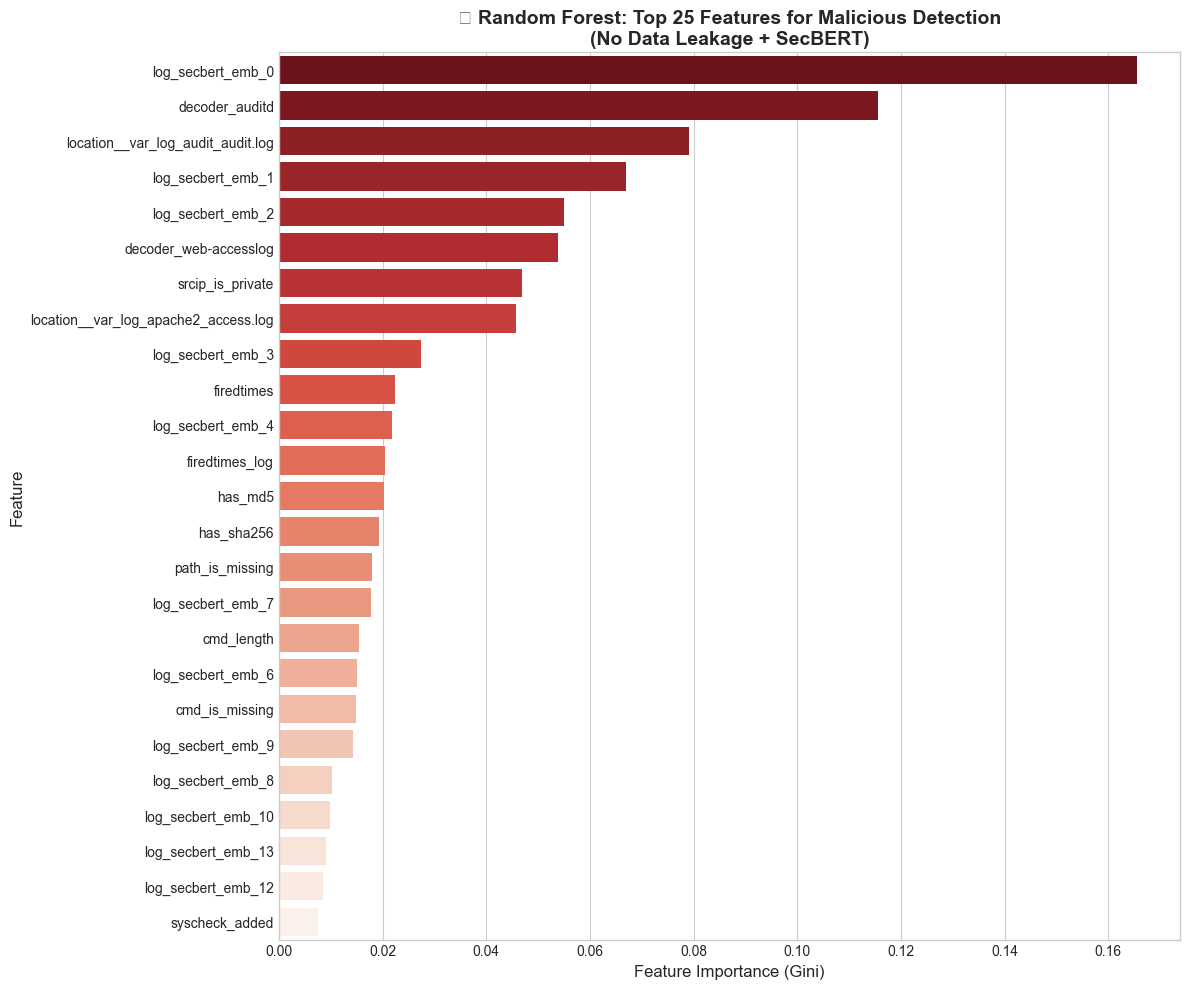

In [8]:
# Train Random Forest for Malicious classification
print("🌲 Training Random Forest Classifier...")
rf_malicious = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)

rf_malicious.fit(X_train_mal, y_train_mal)

# Get feature importances (leakage-free features)
rf_importance_mal = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_malicious.feature_importances_
}).sort_values('Importance', ascending=False)

# Evaluate model
y_pred_rf = rf_malicious.predict(X_test_mal)
rf_accuracy = accuracy_score(y_test_mal, y_pred_rf)

print(f"\n✅ Random Forest trained!")
print(f"   Test Accuracy: {rf_accuracy*100:.2f}%")
print(f"\n📊 Top 20 Features for MALICIOUS Detection (Random Forest):")
print("="*70)
print(rf_importance_mal.head(20).to_string(index=False))

# Visualize
fig, ax = plt.subplots(figsize=(12, 10))
top_n = 25
sns.barplot(data=rf_importance_mal.head(top_n), y='Feature', x='Importance', palette='Reds_r', ax=ax)
ax.set_title(f'🌲 Random Forest: Top {top_n} Features for Malicious Detection\n(No Data Leakage + SecBERT)', fontsize=14, fontweight='bold')
ax.set_xlabel('Feature Importance (Gini)', fontsize=12)
ax.set_ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

### 🚀 A.3 XGBoost Feature Importance

🚀 Training XGBoost Classifier...

✅ XGBoost trained!
   Test Accuracy: 99.70%

📊 Top 20 Features for MALICIOUS Detection (XGBoost):
                         Feature  Importance
                  decoder_auditd    0.782950
            decoder_dpkg-decoder    0.100016
               decoder_rootcheck    0.015744
                  syscheck_added    0.014617
                   decoder_ossec    0.009944
               log_secbert_emb_2    0.008220
                syscheck_deleted    0.005761
               log_secbert_emb_1    0.005511
location_netstat_listening_ports    0.005218
        location__var_log_syslog    0.004797
        decoder_syscheck_deleted    0.004639
          location_wazuh-remoted    0.004633
                      firedtimes    0.004167
                  decoder_kernel    0.003470
               log_secbert_emb_4    0.002702
                srcip_is_private    0.002428
               log_secbert_emb_9    0.002033
               log_secbert_emb_3    0.001990
             

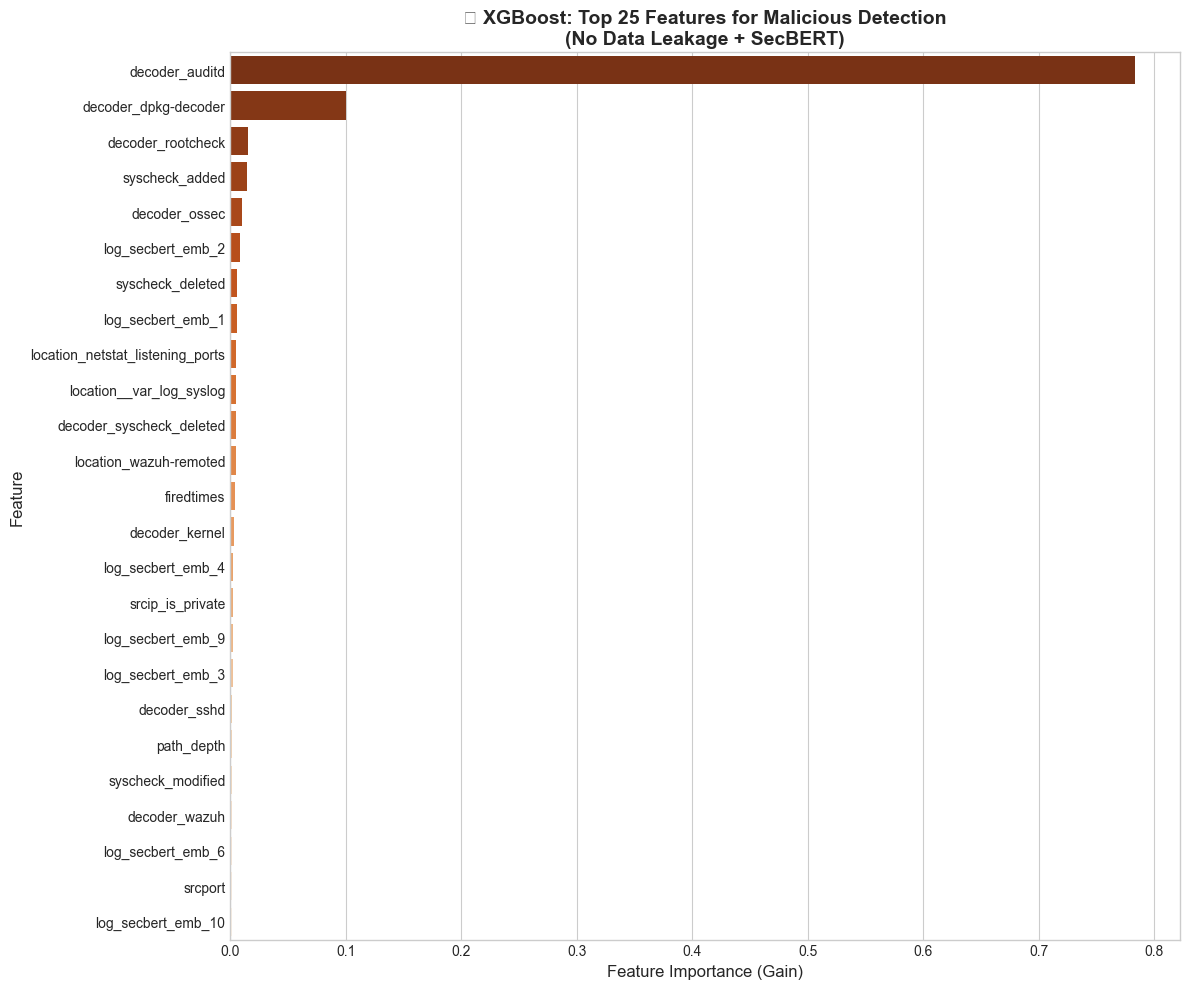

In [9]:
# Train XGBoost for Malicious classification
print("🚀 Training XGBoost Classifier...")

# Calculate scale_pos_weight for imbalanced data
scale_pos_weight = (y_train_mal == 0).sum() / (y_train_mal == 1).sum()

xgb_malicious = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1,
    use_label_encoder=False,
    eval_metric='logloss'
)

xgb_malicious.fit(X_train_mal, y_train_mal)

# Get feature importances (using gain) - leakage-free
xgb_importance_mal = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb_malicious.feature_importances_
}).sort_values('Importance', ascending=False)

# Evaluate
y_pred_xgb = xgb_malicious.predict(X_test_mal)
xgb_accuracy = accuracy_score(y_test_mal, y_pred_xgb)

print(f"\n✅ XGBoost trained!")
print(f"   Test Accuracy: {xgb_accuracy*100:.2f}%")
print(f"\n📊 Top 20 Features for MALICIOUS Detection (XGBoost):")
print("="*70)
print(xgb_importance_mal.head(20).to_string(index=False))

# Visualize
fig, ax = plt.subplots(figsize=(12, 10))
top_n = 25
sns.barplot(data=xgb_importance_mal.head(top_n), y='Feature', x='Importance', palette='Oranges_r', ax=ax)
ax.set_title(f'🚀 XGBoost: Top {top_n} Features for Malicious Detection\n(No Data Leakage + SecBERT)', fontsize=14, fontweight='bold')
ax.set_xlabel('Feature Importance (Gain)', fontsize=12)
ax.set_ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

### 💡 A.4 LightGBM Feature Importance

💡 Training LightGBM Classifier...

✅ LightGBM trained!
   Test Accuracy: 99.65%

📊 Top 20 Features for MALICIOUS Detection (LightGBM):
           Feature  Importance
        firedtimes         899
 log_secbert_emb_0         455
 log_secbert_emb_1         455
log_secbert_emb_15         329
 log_secbert_emb_5         297
 log_secbert_emb_2         291
 log_secbert_emb_6         289
log_secbert_emb_11         285
 log_secbert_emb_9         271
log_secbert_emb_10         269
 log_secbert_emb_8         262
 log_secbert_emb_3         228
 log_secbert_emb_4         208
log_secbert_emb_13         195
log_secbert_emb_14         190
 log_secbert_emb_7         188
log_secbert_emb_12         180
    syscheck_added         101
    decoder_auditd          79
  syscheck_deleted          56


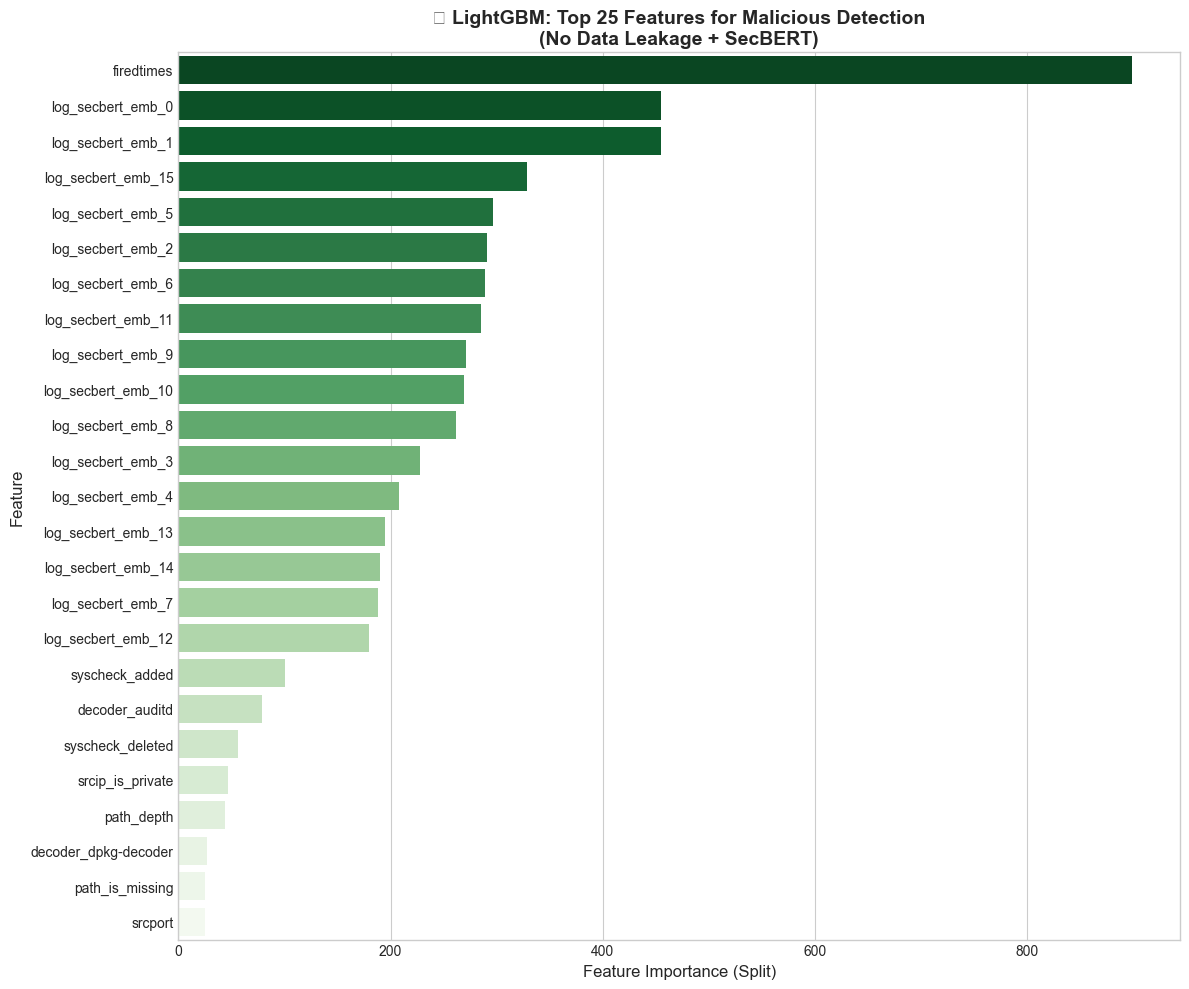

In [10]:
# Train LightGBM for Malicious classification
print("💡 Training LightGBM Classifier...")

lgb_malicious = lgb.LGBMClassifier(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

lgb_malicious.fit(X_train_mal, y_train_mal)

# Get feature importances (leakage-free)
lgb_importance_mal = pd.DataFrame({
    'Feature': X.columns,
    'Importance': lgb_malicious.feature_importances_
}).sort_values('Importance', ascending=False)

# Evaluate
y_pred_lgb = lgb_malicious.predict(X_test_mal)
lgb_accuracy = accuracy_score(y_test_mal, y_pred_lgb)

print(f"\n✅ LightGBM trained!")
print(f"   Test Accuracy: {lgb_accuracy*100:.2f}%")
print(f"\n📊 Top 20 Features for MALICIOUS Detection (LightGBM):")
print("="*70)
print(lgb_importance_mal.head(20).to_string(index=False))

# Visualize
fig, ax = plt.subplots(figsize=(12, 10))
top_n = 25
sns.barplot(data=lgb_importance_mal.head(top_n), y='Feature', x='Importance', palette='Greens_r', ax=ax)
ax.set_title(f'💡 LightGBM: Top {top_n} Features for Malicious Detection\n(No Data Leakage + SecBERT)', fontsize=14, fontweight='bold')
ax.set_xlabel('Feature Importance (Split)', fontsize=12)
ax.set_ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

### 🔀 A.5 Permutation Importance (Model-Agnostic)

🔀 Computing Permutation Importance (subsampled for stability)...

✅ Permutation Importance computed! (on 2000 test samples)

📊 Top 20 Features by Permutation Importance (Malicious Detection):
                     Feature  Importance_Mean  Importance_Std
           log_secbert_emb_1         0.008500        0.000000
                  firedtimes         0.005333        0.001312
              firedtimes_log         0.005000        0.000707
              syscheck_added         0.001500        0.000000
           log_secbert_emb_2         0.001167        0.000471
           log_secbert_emb_9         0.000667        0.000236
          log_secbert_emb_11         0.000667        0.000471
          log_secbert_emb_10         0.000667        0.000471
           log_secbert_emb_5         0.000500        0.000000
          log_secbert_emb_14         0.000500        0.000000
           log_secbert_emb_0         0.000500        0.000707
           log_secbert_emb_8         0.000333        0.000236
  

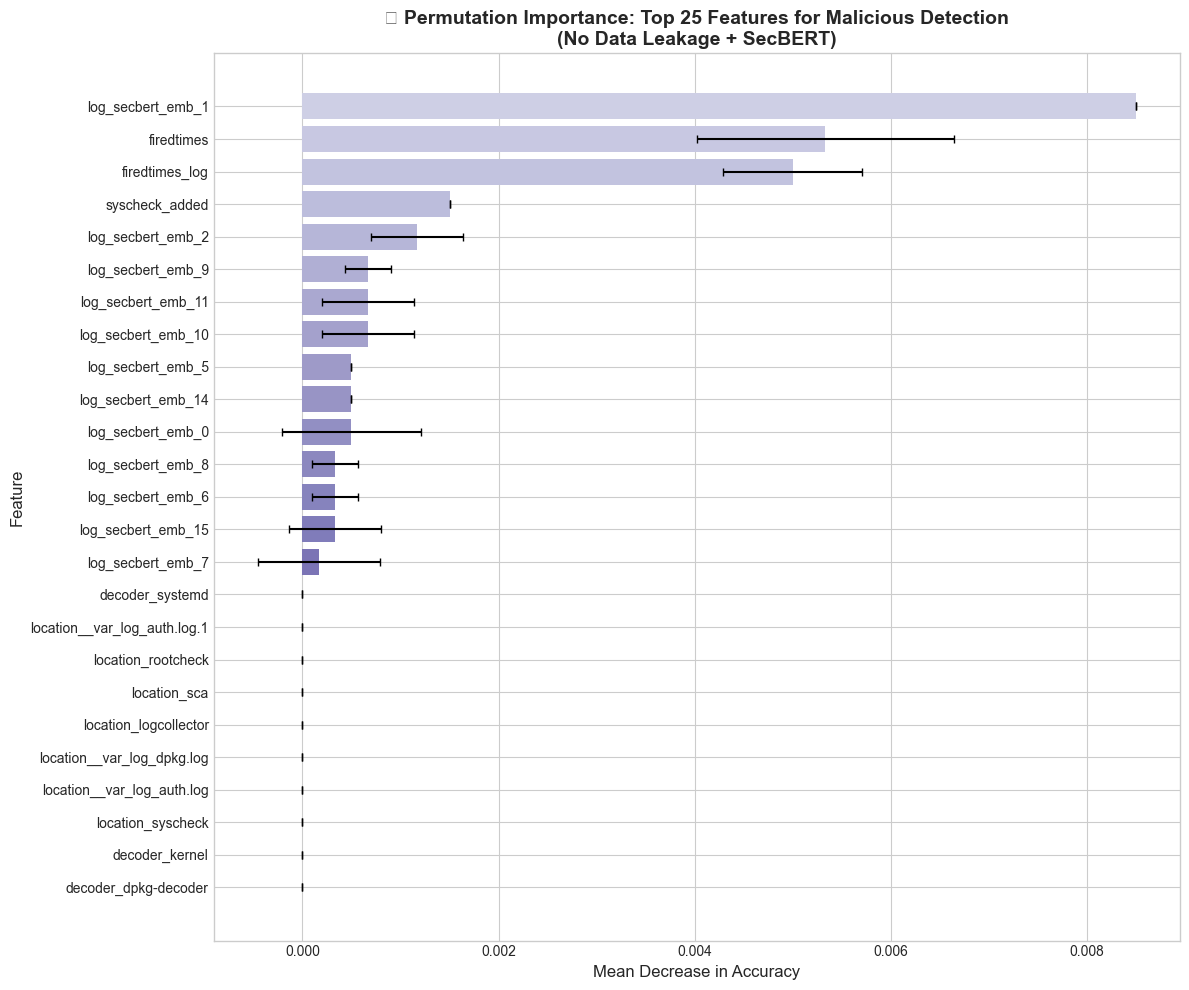

8797

In [11]:
# Permutation Importance using Random Forest (subsampled to avoid OOM)
import gc
gc.collect()

print("🔀 Computing Permutation Importance (subsampled for stability)...")

# Subsample test set to avoid kernel crash
from sklearn.utils import resample
n_subsample = min(2000, len(X_test_mal))
idx = resample(range(len(X_test_mal)), n_samples=n_subsample, random_state=42, replace=False)
X_test_sub = X_test_mal.iloc[idx]
y_test_sub = y_test_mal[idx]

perm_importance = permutation_importance(
    rf_malicious, X_test_sub, y_test_sub,
    n_repeats=3,
    random_state=42,
    n_jobs=1
)

perm_importance_mal = pd.DataFrame({
    'Feature': X.columns,
    'Importance_Mean': perm_importance.importances_mean,
    'Importance_Std': perm_importance.importances_std
}).sort_values('Importance_Mean', ascending=False)

print(f"\n✅ Permutation Importance computed! (on {n_subsample} test samples)")
print(f"\n📊 Top 20 Features by Permutation Importance (Malicious Detection):")
print("="*70)
print(perm_importance_mal.head(20).to_string(index=False))

# Visualize with error bars
fig, ax = plt.subplots(figsize=(12, 10))
top_n = 25
top_perm = perm_importance_mal.head(top_n)
ax.barh(range(top_n), top_perm['Importance_Mean'], xerr=top_perm['Importance_Std'], 
        color=plt.cm.Purples(np.linspace(0.3, 0.9, top_n)), capsize=3)
ax.set_yticks(range(top_n))
ax.set_yticklabels(top_perm['Feature'])
ax.invert_yaxis()
ax.set_title(f'🔀 Permutation Importance: Top {top_n} Features for Malicious Detection\n(No Data Leakage + SecBERT)', fontsize=14, fontweight='bold')
ax.set_xlabel('Mean Decrease in Accuracy', fontsize=12)
ax.set_ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

del X_test_sub, y_test_sub
gc.collect()

### 🎨 A.6 SHAP Values Analysis (Explainability)

🎨 Computing SHAP values for Malicious Detection (Random Forest)...
✅ SHAP values computed for 2000 samples!


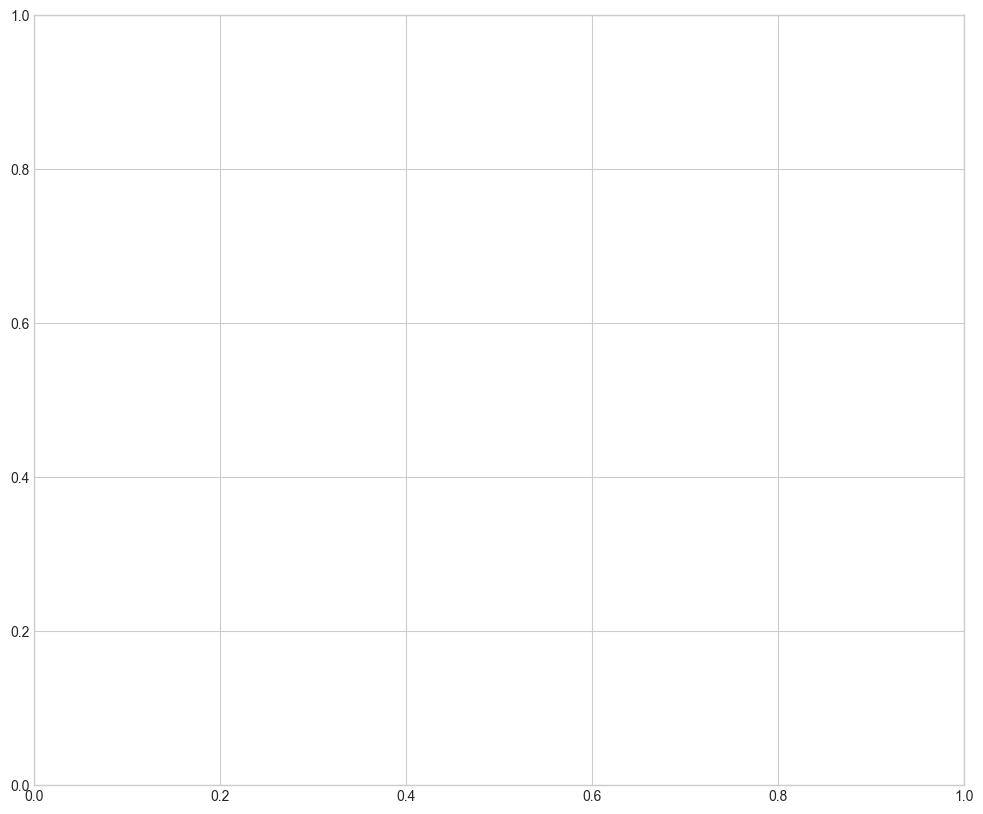

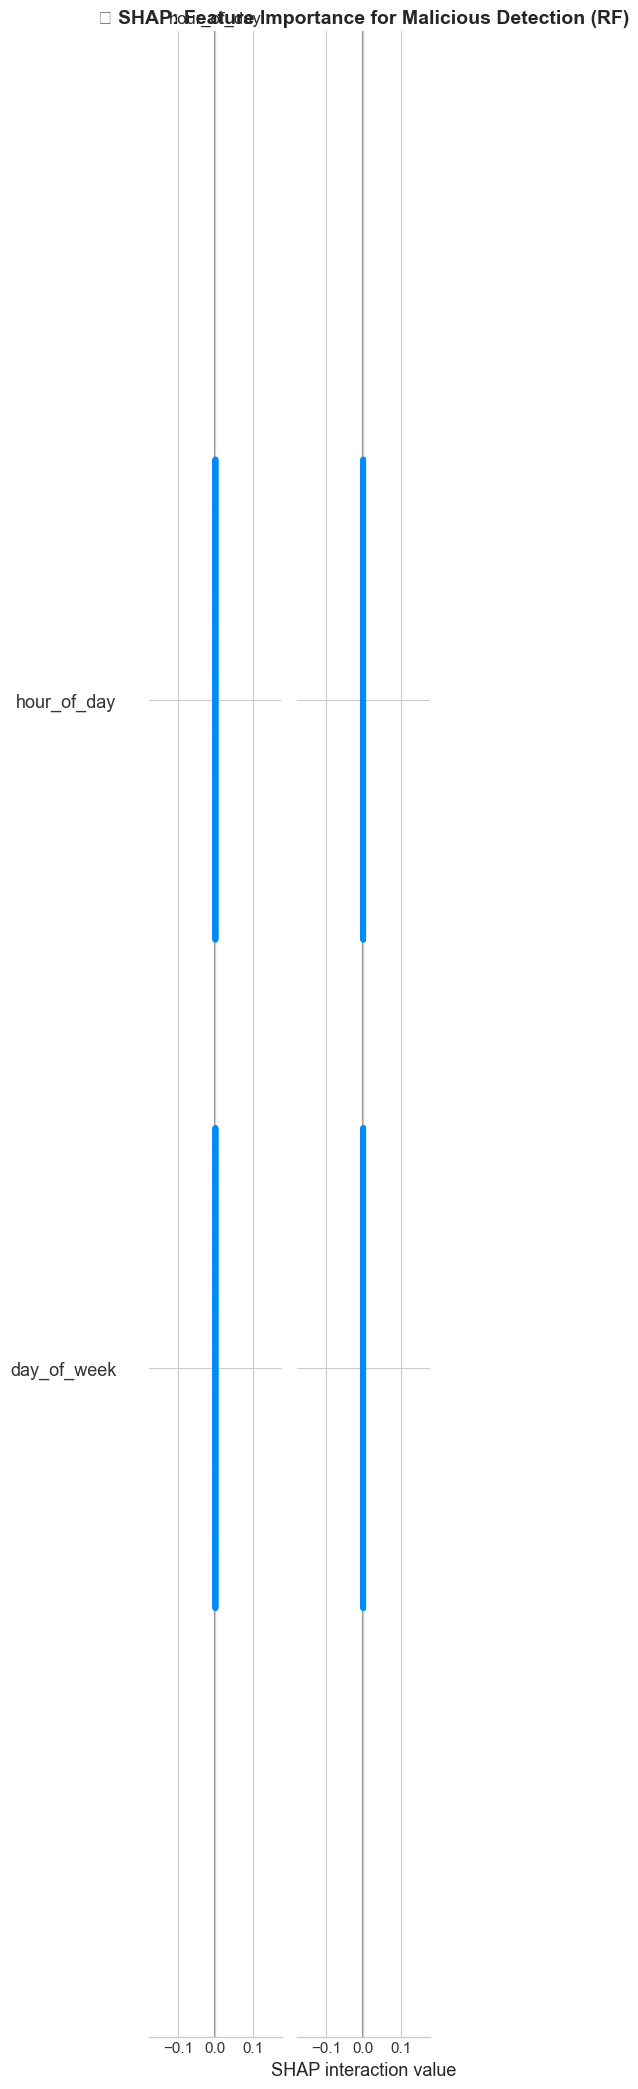

In [13]:
# SHAP Analysis for Random Forest model (Malicious detection)
# Using RF instead of XGBoost due to SHAP/XGBoost version compatibility issue
print("🎨 Computing SHAP values for Malicious Detection (Random Forest)...")

# Use a sample if dataset is large
sample_size = min(2000, len(X_test_mal))
X_sample = X_test_mal.sample(n=sample_size, random_state=42)

# Create SHAP explainer for Random Forest
explainer_mal = shap.TreeExplainer(rf_malicious)
shap_values_mal = explainer_mal.shap_values(X_sample)

# For binary classification, shap_values is a list [class_0, class_1]
if isinstance(shap_values_mal, list):
    shap_values_mal = shap_values_mal[1]  # Use class 1 (malicious)

print(f"✅ SHAP values computed for {sample_size} samples!")

# SHAP Summary Plot - Bar
fig, ax = plt.subplots(figsize=(12, 10))
shap.summary_plot(shap_values_mal, X_sample, plot_type="bar", max_display=25, show=False)
plt.title("🎨 SHAP: Feature Importance for Malicious Detection (RF)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

🐝 SHAP Beeswarm Plot - Shows HOW features affect predictions:


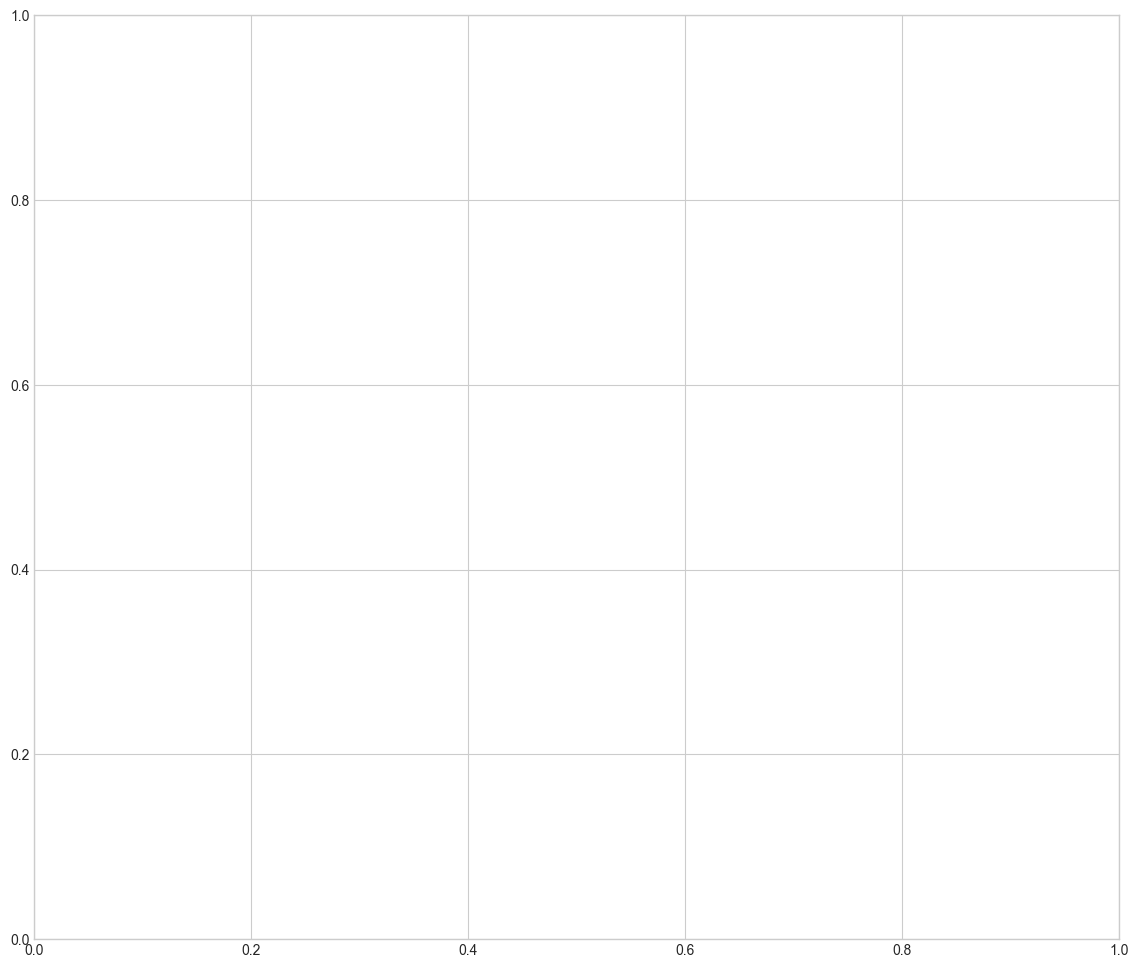

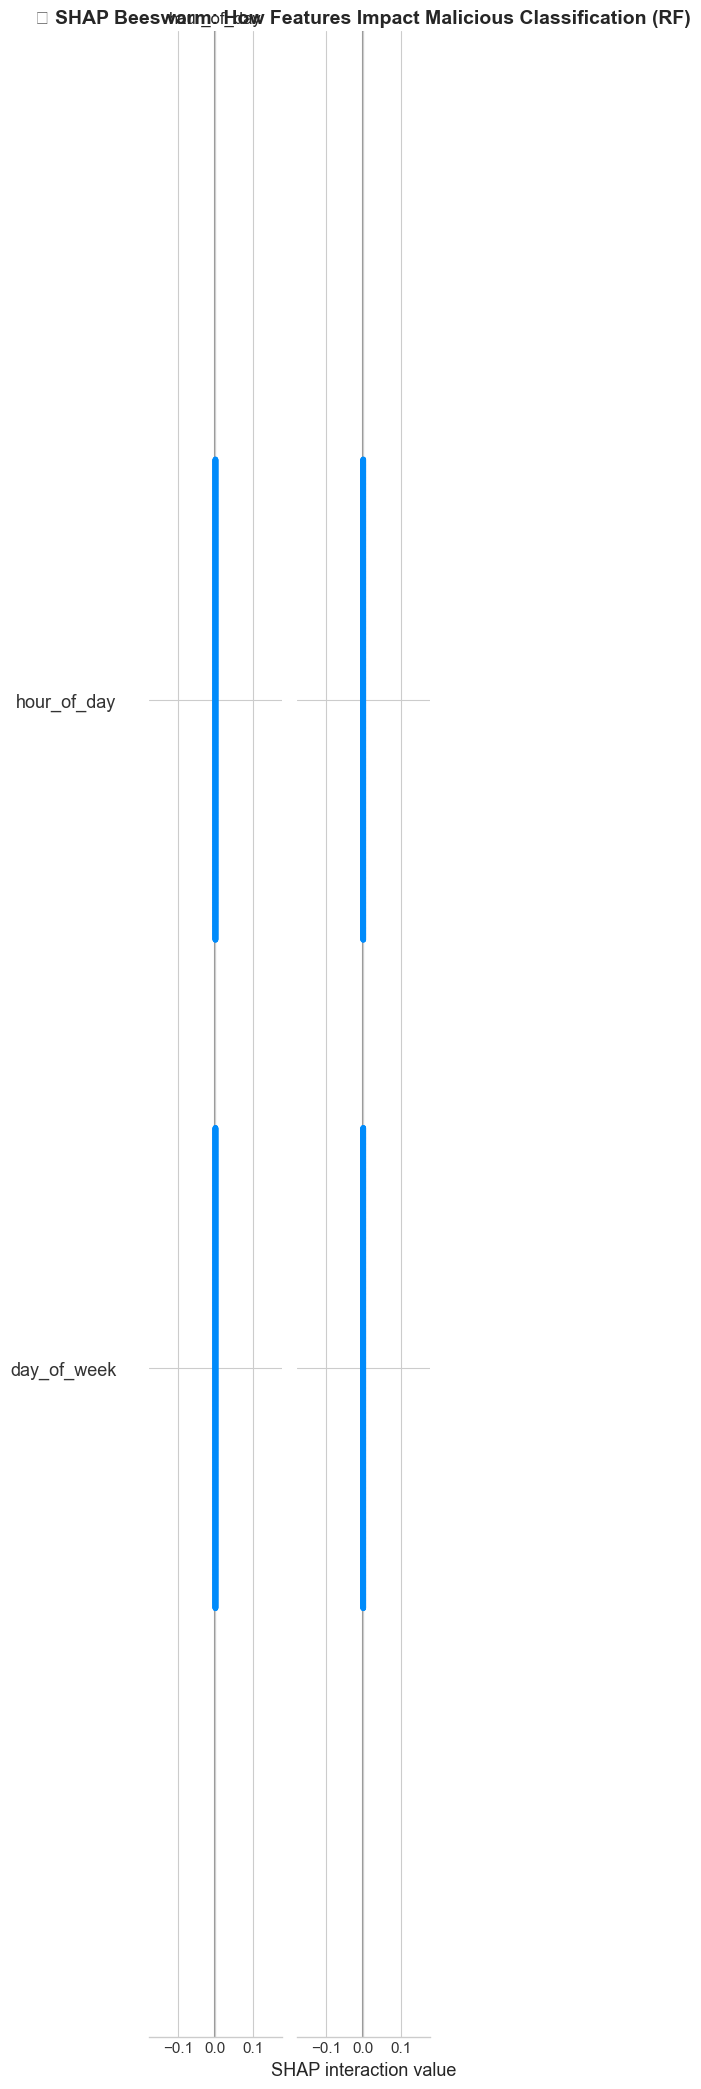


📖 Interpretation:
   - RED dots = HIGH feature values
   - BLUE dots = LOW feature values
   - Position RIGHT of center = Pushes toward MALICIOUS (1)
   - Position LEFT of center = Pushes toward BENIGN (0)


In [14]:
# SHAP Summary Plot - Beeswarm (shows feature value impact direction)
print("🐝 SHAP Beeswarm Plot - Shows HOW features affect predictions:")
fig, ax = plt.subplots(figsize=(14, 12))
shap.summary_plot(shap_values_mal, X_sample, max_display=25, show=False)
plt.title("🎨 SHAP Beeswarm: How Features Impact Malicious Classification (RF)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n📖 Interpretation:")
print("   - RED dots = HIGH feature values")
print("   - BLUE dots = LOW feature values")
print("   - Position RIGHT of center = Pushes toward MALICIOUS (1)")
print("   - Position LEFT of center = Pushes toward BENIGN (0)")

### 📈 A.7 Statistical Feature Selection (Filter Methods)

📈 Computing Mutual Information Scores...

📊 Top 20 Features by Mutual Information (Malicious Detection):
                             Feature  MI_Score
                   log_secbert_emb_1  0.370254
                   log_secbert_emb_0  0.354129
   location__var_log_audit_audit.log  0.319376
                      decoder_auditd  0.317633
                   log_secbert_emb_2  0.233889
                    srcip_is_private  0.191623
location__var_log_apache2_access.log  0.176406
               decoder_web-accesslog  0.174574
                   log_secbert_emb_4  0.171240
                   log_secbert_emb_7  0.167463
                   log_secbert_emb_3  0.131887
                  log_secbert_emb_15  0.126930
                  log_secbert_emb_13  0.122954
                  log_secbert_emb_12  0.120242
                          cmd_length  0.120008
                          has_sha256  0.118901
                             has_md5  0.117897
                     path_is_missing  0.110749
  

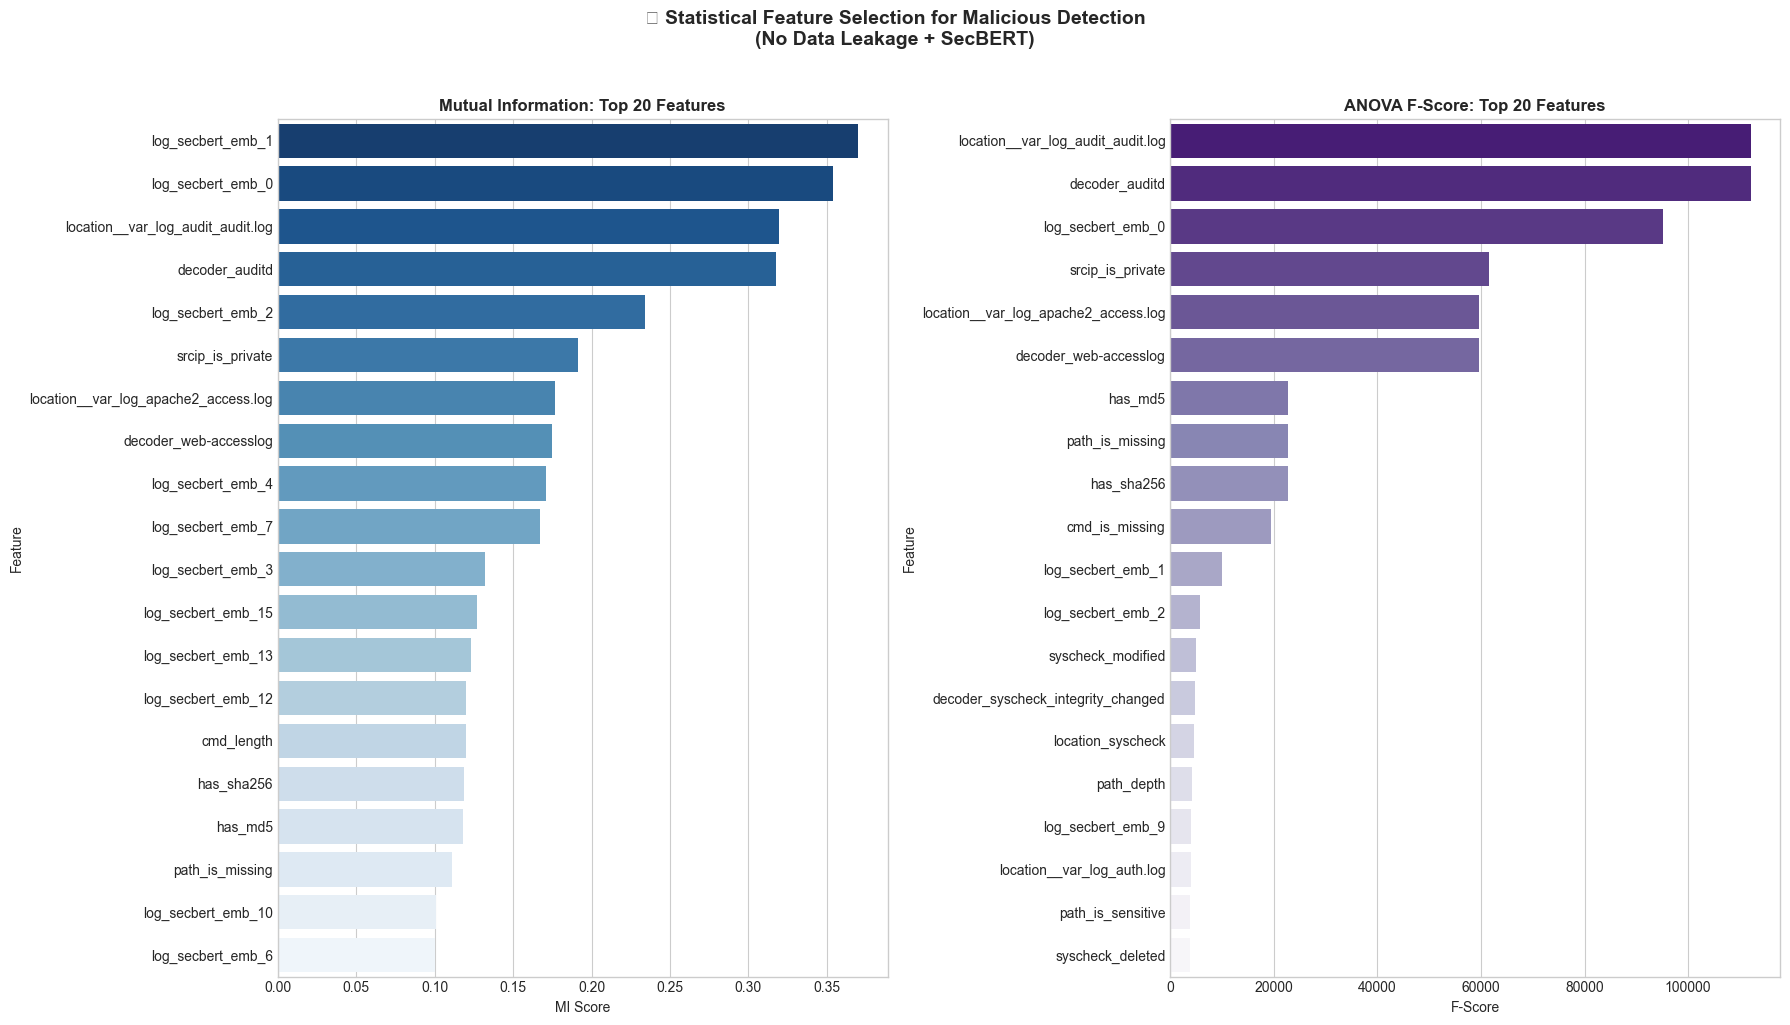

In [15]:
# Mutual Information - measures dependency between features and target
print("📈 Computing Mutual Information Scores...")

mi_scores = mutual_info_classif(X_train_mal, y_train_mal, random_state=42)
mi_importance_mal = pd.DataFrame({
    'Feature': X.columns,
    'MI_Score': mi_scores
}).sort_values('MI_Score', ascending=False)

print(f"\n📊 Top 20 Features by Mutual Information (Malicious Detection):")
print("="*70)
print(mi_importance_mal.head(20).to_string(index=False))

# F-statistic (ANOVA)
print("\n📈 Computing F-statistic (ANOVA) Scores...")
f_scores, p_values = f_classif(X_train_mal, y_train_mal)
f_importance_mal = pd.DataFrame({
    'Feature': X.columns,
    'F_Score': f_scores,
    'P_Value': p_values
}).sort_values('F_Score', ascending=False)

print(f"\n📊 Top 20 Features by F-Score (Malicious Detection):")
print("="*70)
print(f_importance_mal.head(20).to_string(index=False))

# Visualize both
fig, axes = plt.subplots(1, 2, figsize=(18, 10))

# Mutual Information
top_n = 20
sns.barplot(data=mi_importance_mal.head(top_n), y='Feature', x='MI_Score', 
            palette='Blues_r', ax=axes[0])
axes[0].set_title(f'Mutual Information: Top {top_n} Features', fontsize=12, fontweight='bold')
axes[0].set_xlabel('MI Score')

# F-Score
sns.barplot(data=f_importance_mal.head(top_n), y='Feature', x='F_Score', 
            palette='Purples_r', ax=axes[1])
axes[1].set_title(f'ANOVA F-Score: Top {top_n} Features', fontsize=12, fontweight='bold')
axes[1].set_xlabel('F-Score')

plt.suptitle('📈 Statistical Feature Selection for Malicious Detection\n(No Data Leakage + SecBERT)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 📊 A.8 Combined Feature Ranking (Consensus)

📊 Creating Combined Feature Ranking for MALICIOUS Detection...

🏆 TOP 30 FEATURES FOR MALICIOUS DETECTION (Consensus Ranking - No Leakage + SecBERT)
                             Feature       RF      XGB      LGB     Perm       MI  F_Score  Average_Score  Average_Rank
                   log_secbert_emb_1 0.403970 0.007038 0.506118 1.000000 1.000000      NaN       0.583425           3.3
                      decoder_auditd 0.698080 1.000000 0.087875 0.037037 0.857877      NaN       0.536174          27.1
                   log_secbert_emb_0 1.000000 0.001209 0.506118 0.111111 0.956449      NaN       0.514977           8.9
                          firedtimes 0.134873 0.005323 1.000000 0.648148 0.000000      NaN       0.357669          26.7
                   log_secbert_emb_2 0.332637 0.010499 0.323693 0.185185 0.631699      NaN       0.296743           5.4
   location__var_log_audit_audit.log 0.478046 0.000000 0.000000 0.000000 0.862585      NaN       0.268126          61.2
           

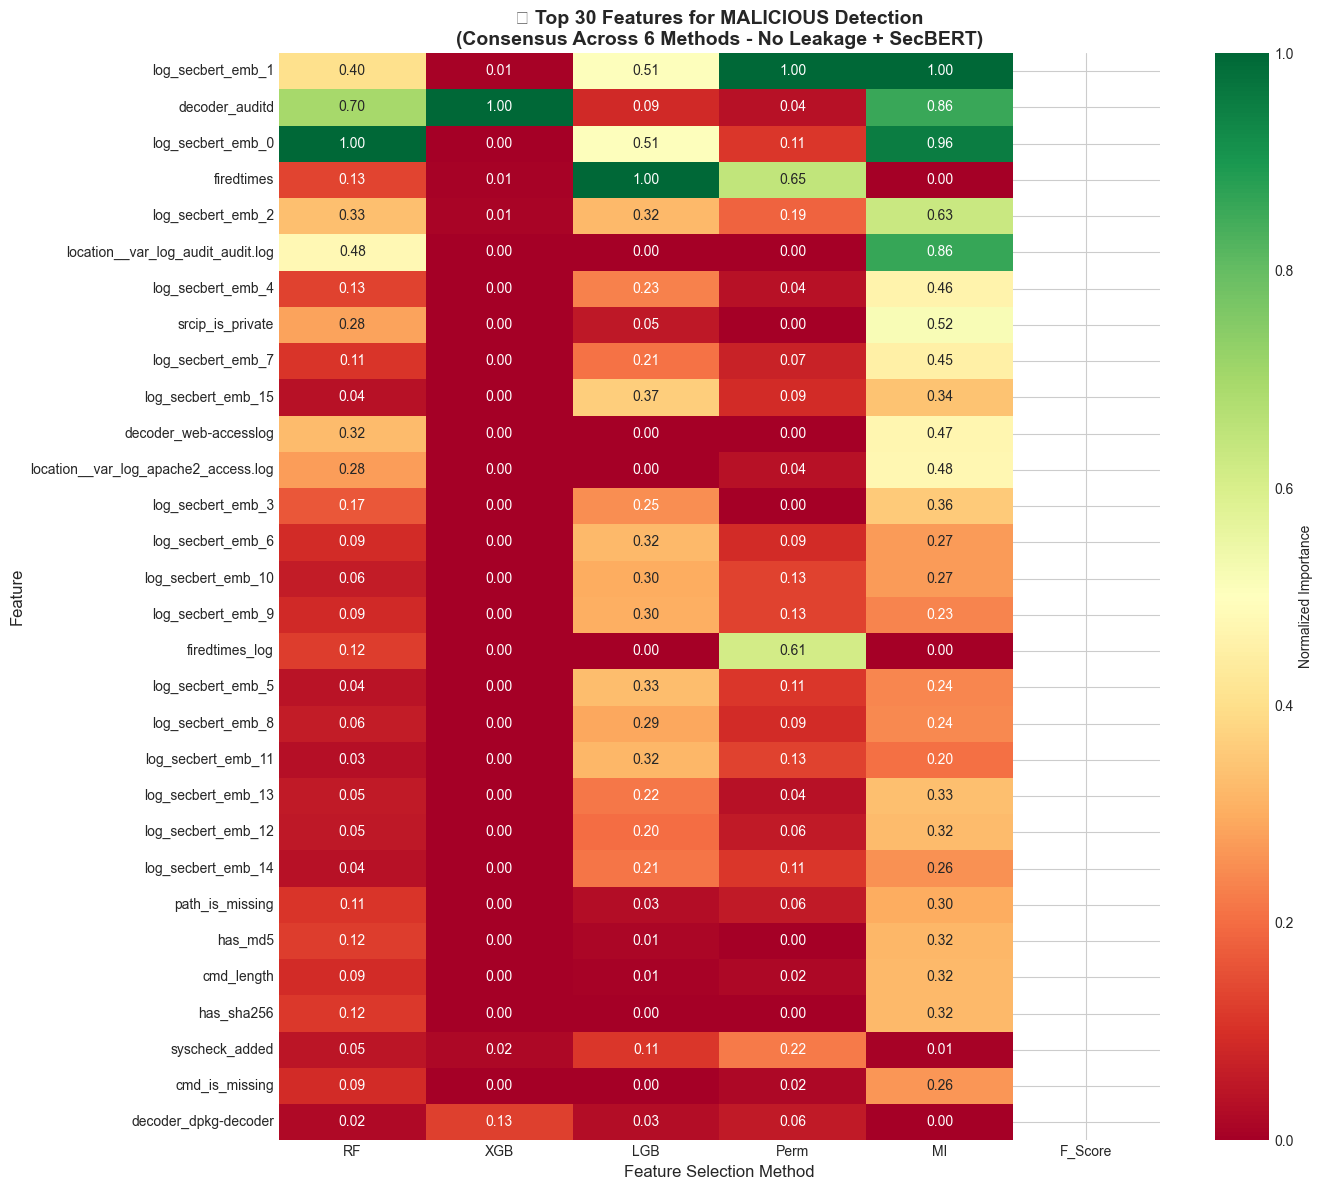

In [16]:
# Combine all importance rankings for consensus
print("📊 Creating Combined Feature Ranking for MALICIOUS Detection...")

# Normalize all importance scores to [0, 1]
def normalize(series):
    return (series - series.min()) / (series.max() - series.min() + 1e-10)

# Create combined dataframe (leakage-free features)
combined_mal = pd.DataFrame({'Feature': X.columns})

# Add normalized scores from each method
combined_mal['RF'] = normalize(rf_importance_mal.set_index('Feature').loc[X.columns, 'Importance'].values)
combined_mal['XGB'] = normalize(xgb_importance_mal.set_index('Feature').loc[X.columns, 'Importance'].values)
combined_mal['LGB'] = normalize(lgb_importance_mal.set_index('Feature').loc[X.columns, 'Importance'].values)
combined_mal['Perm'] = normalize(perm_importance_mal.set_index('Feature').loc[X.columns, 'Importance_Mean'].values)
combined_mal['MI'] = normalize(mi_importance_mal.set_index('Feature').loc[X.columns, 'MI_Score'].values)
combined_mal['F_Score'] = normalize(f_importance_mal.set_index('Feature').loc[X.columns, 'F_Score'].values)

# Calculate average score
combined_mal['Average_Score'] = combined_mal[['RF', 'XGB', 'LGB', 'Perm', 'MI', 'F_Score']].mean(axis=1)

# Calculate rank for each method
for col in ['RF', 'XGB', 'LGB', 'Perm', 'MI', 'F_Score']:
    combined_mal[f'{col}_Rank'] = combined_mal[col].rank(ascending=False)

combined_mal['Average_Rank'] = combined_mal[[f'{col}_Rank' for col in ['RF', 'XGB', 'LGB', 'Perm', 'MI', 'F_Score']]].mean(axis=1)

# Sort by average score
combined_mal = combined_mal.sort_values('Average_Score', ascending=False)

print("\n" + "="*100)
print("🏆 TOP 30 FEATURES FOR MALICIOUS DETECTION (Consensus Ranking - No Leakage + SecBERT)")
print("="*100)
display_cols = ['Feature', 'RF', 'XGB', 'LGB', 'Perm', 'MI', 'F_Score', 'Average_Score', 'Average_Rank']
print(combined_mal[display_cols].head(30).to_string(index=False))

# Visualize
fig, ax = plt.subplots(figsize=(14, 12))
top_n = 30
top_features = combined_mal.head(top_n)

# Create heatmap data
heatmap_data = top_features.set_index('Feature')[['RF', 'XGB', 'LGB', 'Perm', 'MI', 'F_Score']]
sns.heatmap(heatmap_data, annot=True, fmt='.2f', cmap='RdYlGn', ax=ax, 
            cbar_kws={'label': 'Normalized Importance'})
ax.set_title('🏆 Top 30 Features for MALICIOUS Detection\n(Consensus Across 6 Methods - No Leakage + SecBERT)', 
             fontsize=14, fontweight='bold')
ax.set_xlabel('Feature Selection Method', fontsize=12)
ax.set_ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

### ✅ Summary: Malicious Detection Results (NO DATA LEAKAGE)

In [17]:
# ============================================================================
# 📊 SUMMARY: MALICIOUS DETECTION RESULTS (FULLY LEAKAGE-FREE + SecBERT)
# ============================================================================

print("="*80)
print("📊 MALICIOUS DETECTION RESULTS - FULLY LEAKAGE-FREE + SecBERT!")
print("="*80)

print(f"\n🛡️ EXCLUDED FEATURES (Data Leakage Prevention):")
print(f"   ❌ rule_level, is_high_severity, is_critical_severity")
print(f"   ❌ MITRE tactic/technique features (14+3)")
print(f"   ❌ rule.description text features")
print(f"   Features used: {X.shape[1]}")

print(f"\n🤖 NEW FEATURES ADDED:")
print(f"   ✅ SecBERT command embeddings (16 dims)")
print(f"   ✅ SecBERT full_log embeddings (16 dims)")

print(f"\n📈 MODEL ACCURACIES (REAL - NO DATA LEAKAGE):")
print("-"*50)
print(f"   🌲 Random Forest:  {rf_accuracy*100:.2f}%")
print(f"   🚀 XGBoost:        {xgb_accuracy*100:.2f}%")
print(f"   💡 LightGBM:       {lgb_accuracy*100:.2f}%")

print(f"\n🏆 TOP 10 MOST IMPORTANT FEATURES (Consensus):")
print("-"*50)
top_10_features = combined_mal.head(10)[['Feature', 'Average_Score']].values
for i, (feat, score) in enumerate(top_10_features, 1):
    print(f"   {i:2d}. {feat:40s} (score: {score:.3f})")

print("\n" + "="*80)
print("✅ These results are RELIABLE - no data leakage!")
print("✅ SecBERT adds semantic understanding of commands and logs!")
print("="*80)

📊 MALICIOUS DETECTION RESULTS - FULLY LEAKAGE-FREE + SecBERT!

🛡️ EXCLUDED FEATURES (Data Leakage Prevention):
   ❌ rule_level, is_high_severity, is_critical_severity
   ❌ MITRE tactic/technique features (14+3)
   ❌ rule.description text features
   Features used: 119

🤖 NEW FEATURES ADDED:
   ✅ SecBERT command embeddings (16 dims)
   ✅ SecBERT full_log embeddings (16 dims)

📈 MODEL ACCURACIES (REAL - NO DATA LEAKAGE):
--------------------------------------------------
   🌲 Random Forest:  99.39%
   🚀 XGBoost:        99.70%
   💡 LightGBM:       99.65%

🏆 TOP 10 MOST IMPORTANT FEATURES (Consensus):
--------------------------------------------------
    1. log_secbert_emb_1                        (score: 0.583)
    2. decoder_auditd                           (score: 0.536)
    3. log_secbert_emb_0                        (score: 0.515)
    4. firedtimes                               (score: 0.358)
    5. log_secbert_emb_2                        (score: 0.297)
    6. location__var_log_audi

---
# 🔗 PART B: Feature Importance for CYBER KILL CHAIN Stage Classification

## Which features determine the STAGE of an attack in the Cyber Kill Chain?

The Cyber Kill Chain stages typically include:
1. **Reconnaissance** - Gathering information about the target
2. **Weaponization** - Creating attack tools
3. **Delivery** - Transmitting the attack
4. **Exploitation** - Executing malicious code
5. **Installation** - Installing malware
6. **Command & Control (C2)** - Remote communication
7. **Actions on Objectives** - Achieving attacker goals

### 📊 B.1 Prepare Data for CKC Classification (Malicious samples only)

In [18]:
# For CKC stage prediction, we focus on MALICIOUS samples only
# (benign samples don't have a meaningful CKC stage)

print("📊 Preparing Data for Cyber Kill Chain Stage Classification...")
print("="*70)

# Filter to malicious samples with valid CKC labels
malicious_mask = df['malicious'] == 1
ckc_valid_mask = df['cyber_kill_chain_tactic'].notna() & (df['cyber_kill_chain_tactic'] != 'Unknown')

# Combine masks
valid_ckc_mask = malicious_mask & ckc_valid_mask

X_ckc = X[valid_ckc_mask].copy()
y_ckc_filtered = df.loc[valid_ckc_mask, 'cyber_kill_chain_tactic'].values

print(f"✅ Total malicious samples: {malicious_mask.sum():,}")
print(f"✅ Samples with valid CKC stage: {valid_ckc_mask.sum():,}")

# Show CKC distribution
print(f"\n📊 Cyber Kill Chain Stage Distribution:")
print("-"*50)
ckc_dist = pd.Series(y_ckc_filtered).value_counts()
for stage, count in ckc_dist.items():
    print(f"   {stage}: {count:,} samples ({count/len(y_ckc_filtered)*100:.1f}%)")

# Encode CKC labels
ckc_label_encoder = LabelEncoder()
y_ckc_encoded_filtered = ckc_label_encoder.fit_transform(y_ckc_filtered)

print(f"\n🏷️ CKC Classes ({len(ckc_label_encoder.classes_)} total):")
for i, cls in enumerate(ckc_label_encoder.classes_):
    print(f"   {i}: {cls}")

📊 Preparing Data for Cyber Kill Chain Stage Classification...
✅ Total malicious samples: 25,418
✅ Samples with valid CKC stage: 24,548

📊 Cyber Kill Chain Stage Distribution:
--------------------------------------------------
   S3: 16,556 samples (67.4%)
   S4: 4,291 samples (17.5%)
   S7: 1,777 samples (7.2%)
   S5: 1,281 samples (5.2%)
   S1: 643 samples (2.6%)

🏷️ CKC Classes (5 total):
   0: S1
   1: S3
   2: S4
   3: S5
   4: S7


In [19]:
# Train/Test split for CKC classification
X_train_ckc, X_test_ckc, y_train_ckc, y_test_ckc = train_test_split(
    X_ckc, y_ckc_encoded_filtered, test_size=0.2, random_state=42, stratify=y_ckc_encoded_filtered
)

print("📊 Data Split for CKC Stage Classification:")
print(f"   Training set: {X_train_ckc.shape[0]:,} samples")
print(f"   Test set: {X_test_ckc.shape[0]:,} samples")

# Show distribution in train/test
print("\n📊 Training Set Distribution:")
for i, cls in enumerate(ckc_label_encoder.classes_):
    count = (y_train_ckc == i).sum()
    print(f"   {cls}: {count} samples")

print("\n📊 Test Set Distribution:")
for i, cls in enumerate(ckc_label_encoder.classes_):
    count = (y_test_ckc == i).sum()
    print(f"   {cls}: {count} samples")

📊 Data Split for CKC Stage Classification:
   Training set: 19,638 samples
   Test set: 4,910 samples

📊 Training Set Distribution:
   S1: 514 samples
   S3: 13244 samples
   S4: 3433 samples
   S5: 1025 samples
   S7: 1422 samples

📊 Test Set Distribution:
   S1: 129 samples
   S3: 3312 samples
   S4: 858 samples
   S5: 256 samples
   S7: 355 samples


### 🌲 B.2 Random Forest Feature Importance for CKC Stages

🌲 Training Random Forest for CKC Stage Classification...

✅ Random Forest trained!
   Test Accuracy: 93.87%

📊 Top 20 Features for CKC STAGE Detection (Random Forest):
                 Feature  Importance
              firedtimes    0.064428
       log_secbert_emb_1    0.062074
       log_secbert_emb_2    0.060219
          firedtimes_log    0.052475
       log_secbert_emb_4    0.046514
        syscheck_deleted    0.042639
decoder_syscheck_deleted    0.039295
       log_secbert_emb_8    0.038562
         path_is_missing    0.035916
       log_secbert_emb_0    0.034429
       log_secbert_emb_6    0.033939
       log_secbert_emb_5    0.030930
                 has_md5    0.029045
              path_depth    0.029023
      log_secbert_emb_14    0.027696
              has_sha256    0.025715
       syscheck_modified    0.024158
       location_syscheck    0.022598
      log_secbert_emb_13    0.022121
       log_secbert_emb_9    0.019638


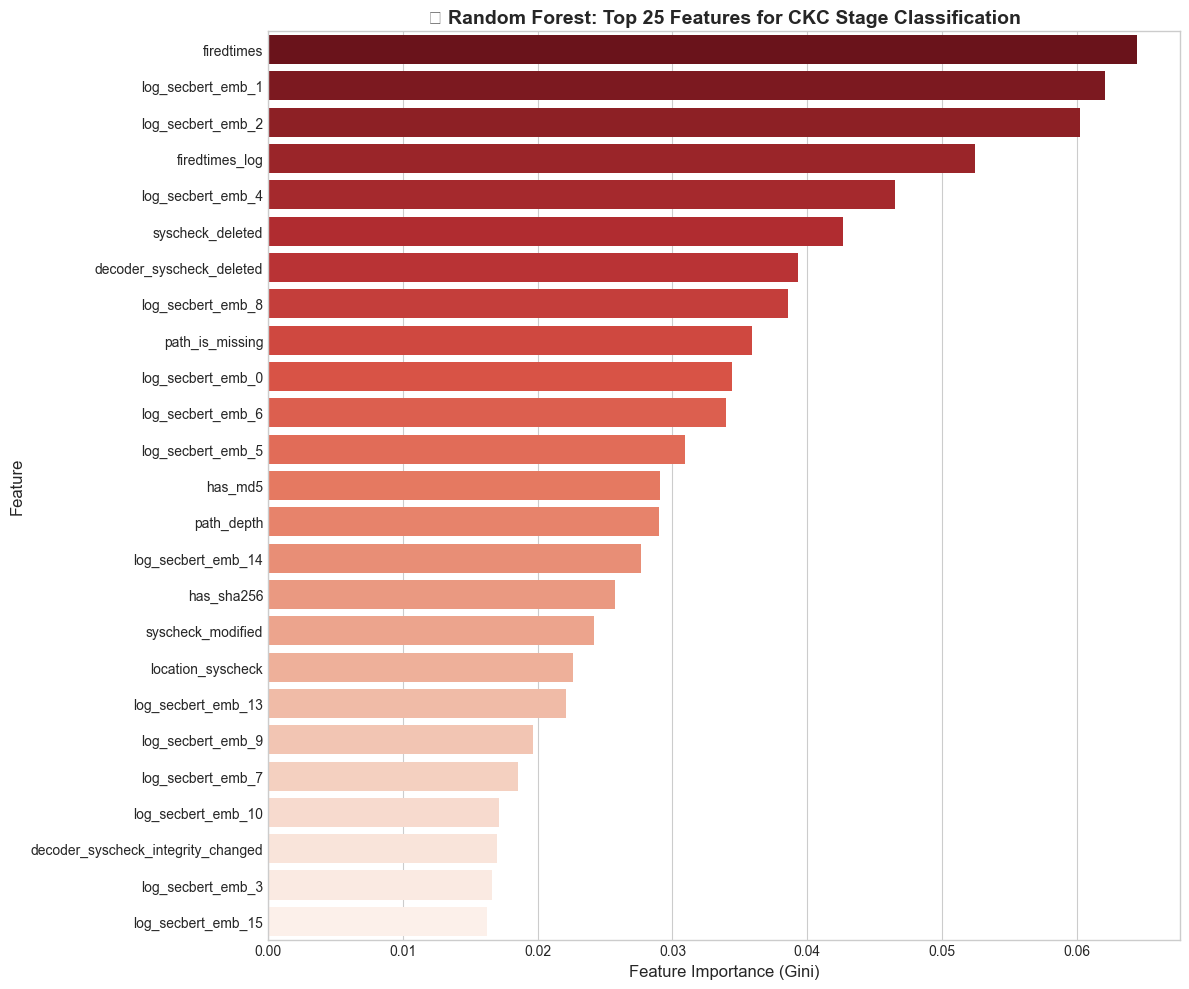


📊 Classification Report for CKC Stages:
----------------------------------------------------------------------
              precision    recall  f1-score   support

          S1       0.89      0.90      0.89       129
          S3       0.99      0.92      0.95      3312
          S4       0.76      0.97      0.85       858
          S5       1.00      1.00      1.00       256
          S7       1.00      1.00      1.00       355

    accuracy                           0.94      4910
   macro avg       0.93      0.96      0.94      4910
weighted avg       0.95      0.94      0.94      4910



In [20]:
# Train Random Forest for CKC Stage classification (Multi-class)
print("🌲 Training Random Forest for CKC Stage Classification...")

rf_ckc = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)

rf_ckc.fit(X_train_ckc, y_train_ckc)

# Get feature importances
rf_importance_ckc = pd.DataFrame({
    'Feature': X_ckc.columns,
    'Importance': rf_ckc.feature_importances_
}).sort_values('Importance', ascending=False)

# Evaluate
y_pred_rf_ckc = rf_ckc.predict(X_test_ckc)
rf_accuracy_ckc = accuracy_score(y_test_ckc, y_pred_rf_ckc)

print(f"\n✅ Random Forest trained!")
print(f"   Test Accuracy: {rf_accuracy_ckc*100:.2f}%")
print(f"\n📊 Top 20 Features for CKC STAGE Detection (Random Forest):")
print("="*70)
print(rf_importance_ckc.head(20).to_string(index=False))

# Visualize
fig, ax = plt.subplots(figsize=(12, 10))
top_n = 25
sns.barplot(data=rf_importance_ckc.head(top_n), y='Feature', x='Importance', palette='Reds_r', ax=ax)
ax.set_title(f'🌲 Random Forest: Top {top_n} Features for CKC Stage Classification', fontsize=14, fontweight='bold')
ax.set_xlabel('Feature Importance (Gini)', fontsize=12)
ax.set_ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

# Show classification report
print("\n📊 Classification Report for CKC Stages:")
print("-"*70)
print(classification_report(y_test_ckc, y_pred_rf_ckc, 
                            target_names=ckc_label_encoder.classes_))

### 🚀 B.3 XGBoost Feature Importance for CKC Stages

🚀 Training XGBoost for CKC Stage Classification...

✅ XGBoost trained!
   Test Accuracy: 98.25%

📊 Top 20 Features for CKC STAGE Detection (XGBoost):
                   Feature  Importance
         syscheck_modified    0.425378
          syscheck_deleted    0.200047
               decoder_pam    0.140377
                cmd_length    0.099885
    location_wazuh-remoted    0.020970
           path_is_missing    0.018145
                path_depth    0.016064
         cmd_pipe_redirect    0.012345
location__var_log_auth.log    0.008054
         log_secbert_emb_2    0.007569
                firedtimes    0.006295
         log_secbert_emb_4    0.005325
          srcip_is_private    0.003902
         log_secbert_emb_6    0.003733
         log_secbert_emb_0    0.003665
         log_secbert_emb_1    0.003370
     decoder_web-accesslog    0.002280
     location_logcollector    0.001946
             decoder_ossec    0.001524
         log_secbert_emb_7    0.001430


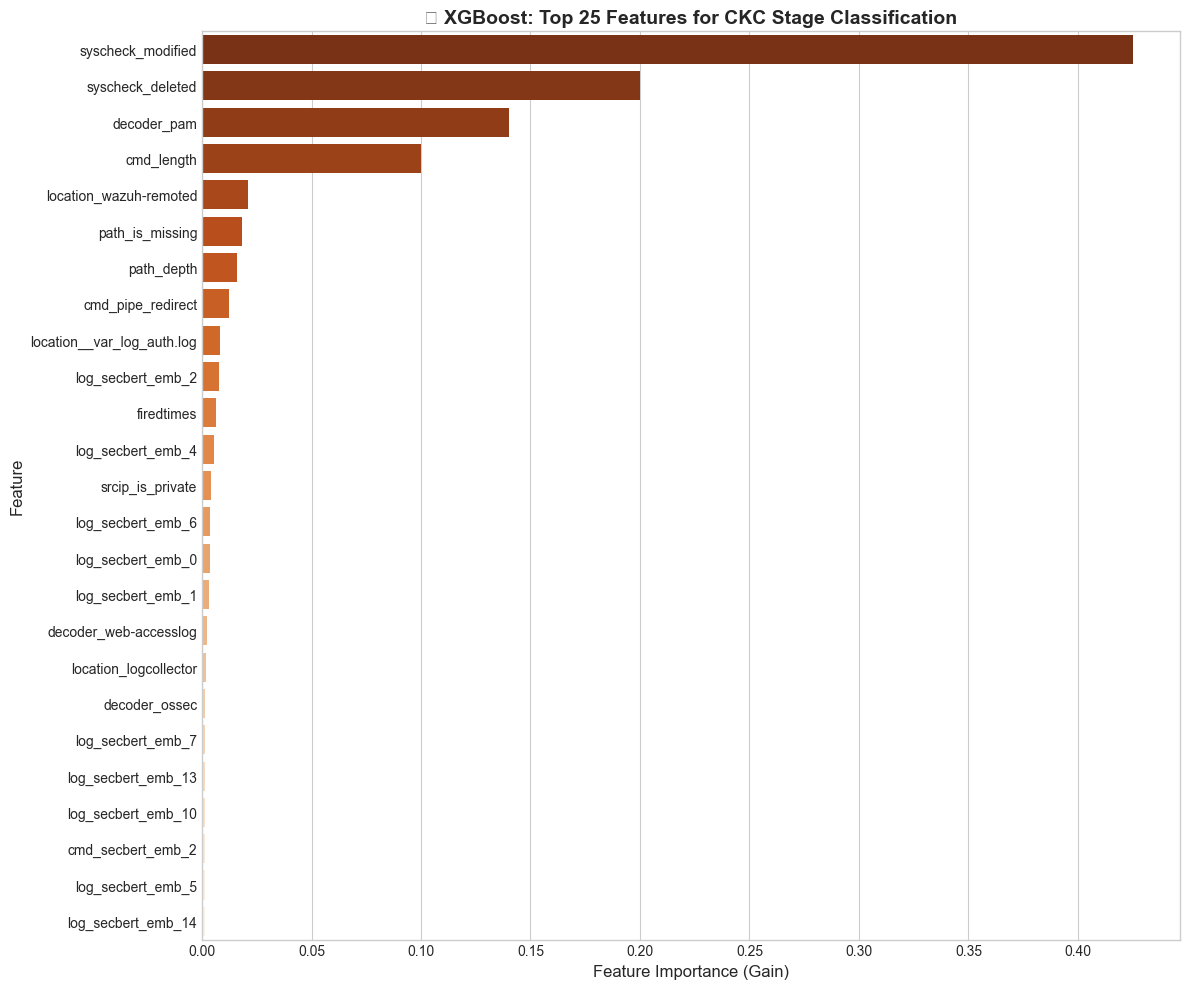

In [21]:
# Train XGBoost for CKC Stage classification (Multi-class)
print("🚀 Training XGBoost for CKC Stage Classification...")

xgb_ckc = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    use_label_encoder=False,
    eval_metric='mlogloss',
    objective='multi:softmax'
)

xgb_ckc.fit(X_train_ckc, y_train_ckc)

# Get feature importances
xgb_importance_ckc = pd.DataFrame({
    'Feature': X_ckc.columns,
    'Importance': xgb_ckc.feature_importances_
}).sort_values('Importance', ascending=False)

# Evaluate
y_pred_xgb_ckc = xgb_ckc.predict(X_test_ckc)
xgb_accuracy_ckc = accuracy_score(y_test_ckc, y_pred_xgb_ckc)

print(f"\n✅ XGBoost trained!")
print(f"   Test Accuracy: {xgb_accuracy_ckc*100:.2f}%")
print(f"\n📊 Top 20 Features for CKC STAGE Detection (XGBoost):")
print("="*70)
print(xgb_importance_ckc.head(20).to_string(index=False))

# Visualize
fig, ax = plt.subplots(figsize=(12, 10))
top_n = 25
sns.barplot(data=xgb_importance_ckc.head(top_n), y='Feature', x='Importance', palette='Oranges_r', ax=ax)
ax.set_title(f'🚀 XGBoost: Top {top_n} Features for CKC Stage Classification', fontsize=14, fontweight='bold')
ax.set_xlabel('Feature Importance (Gain)', fontsize=12)
ax.set_ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

### 💡 B.4 LightGBM Feature Importance for CKC Stages

💡 Training LightGBM for CKC Stage Classification...

✅ LightGBM trained!
   Test Accuracy: 98.27%

📊 Top 20 Features for CKC STAGE Detection (LightGBM):
              Feature  Importance
           firedtimes        4039
    log_secbert_emb_1        1875
    log_secbert_emb_0        1562
    log_secbert_emb_9        1479
   log_secbert_emb_13        1435
    log_secbert_emb_2        1413
   log_secbert_emb_12        1368
    log_secbert_emb_7        1305
   log_secbert_emb_14        1269
    log_secbert_emb_5        1262
    log_secbert_emb_3        1222
    log_secbert_emb_4        1185
   log_secbert_emb_15        1126
    log_secbert_emb_6        1105
   log_secbert_emb_10        1087
   log_secbert_emb_11        1064
    log_secbert_emb_8        1003
     srcip_is_private         181
decoder_web-accesslog         122
           cmd_length         108


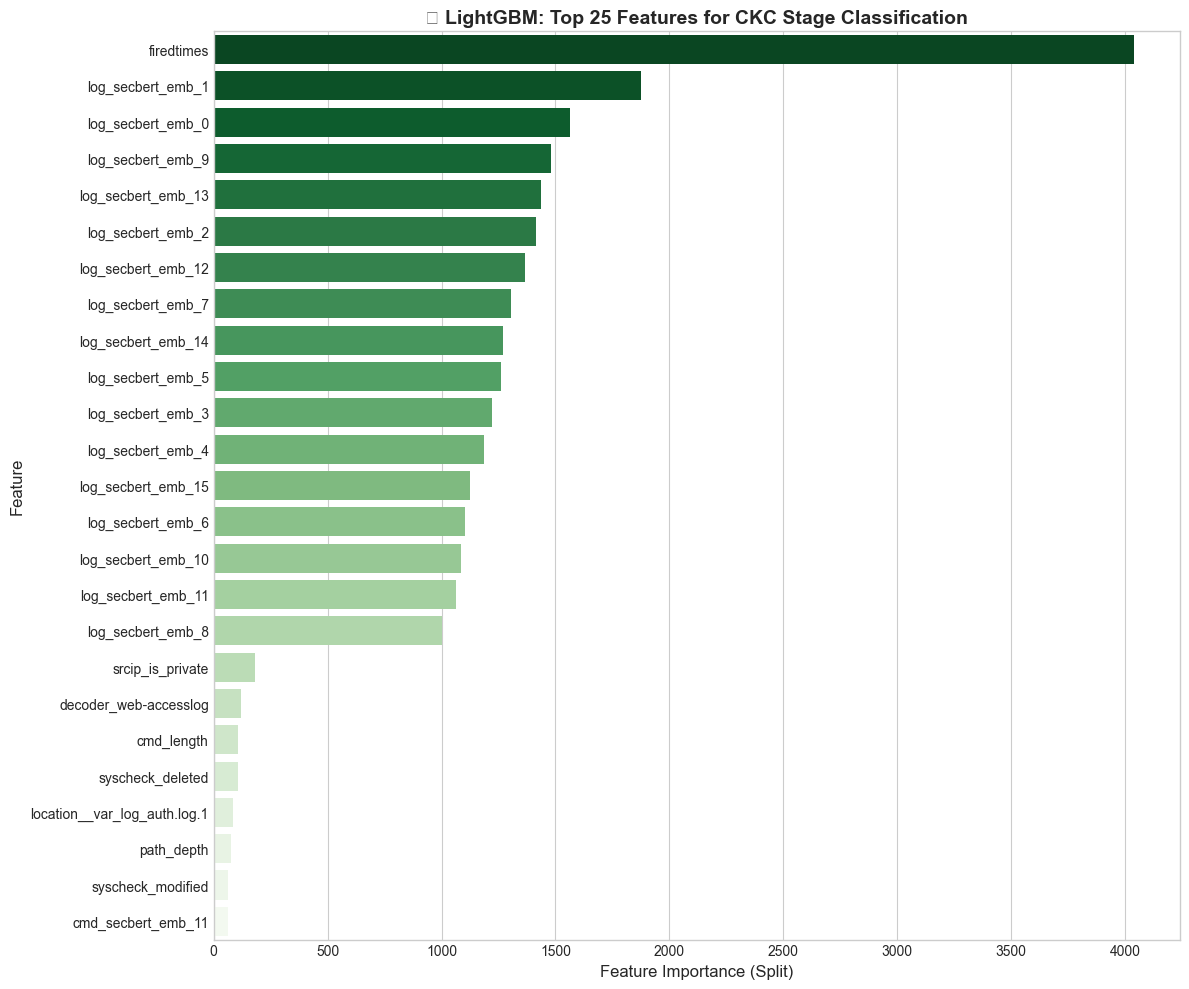

In [22]:
# Train LightGBM for CKC Stage classification
print("💡 Training LightGBM for CKC Stage Classification...")

lgb_ckc = lgb.LGBMClassifier(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=-1,
    objective='multiclass'
)

lgb_ckc.fit(X_train_ckc, y_train_ckc)

# Get feature importances
lgb_importance_ckc = pd.DataFrame({
    'Feature': X_ckc.columns,
    'Importance': lgb_ckc.feature_importances_
}).sort_values('Importance', ascending=False)

# Evaluate
y_pred_lgb_ckc = lgb_ckc.predict(X_test_ckc)
lgb_accuracy_ckc = accuracy_score(y_test_ckc, y_pred_lgb_ckc)

print(f"\n✅ LightGBM trained!")
print(f"   Test Accuracy: {lgb_accuracy_ckc*100:.2f}%")
print(f"\n📊 Top 20 Features for CKC STAGE Detection (LightGBM):")
print("="*70)
print(lgb_importance_ckc.head(20).to_string(index=False))

# Visualize
fig, ax = plt.subplots(figsize=(12, 10))
top_n = 25
sns.barplot(data=lgb_importance_ckc.head(top_n), y='Feature', x='Importance', palette='Greens_r', ax=ax)
ax.set_title(f'💡 LightGBM: Top {top_n} Features for CKC Stage Classification', fontsize=14, fontweight='bold')
ax.set_xlabel('Feature Importance (Split)', fontsize=12)
ax.set_ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

### 🎨 B.5 SHAP Analysis for CKC Stages (Per-Class Feature Impact)

🎨 Computing SHAP values for CKC Stage Classification (Random Forest)...
   (This shows which features are important for EACH CKC stage)
✅ SHAP values computed for 1500 samples!


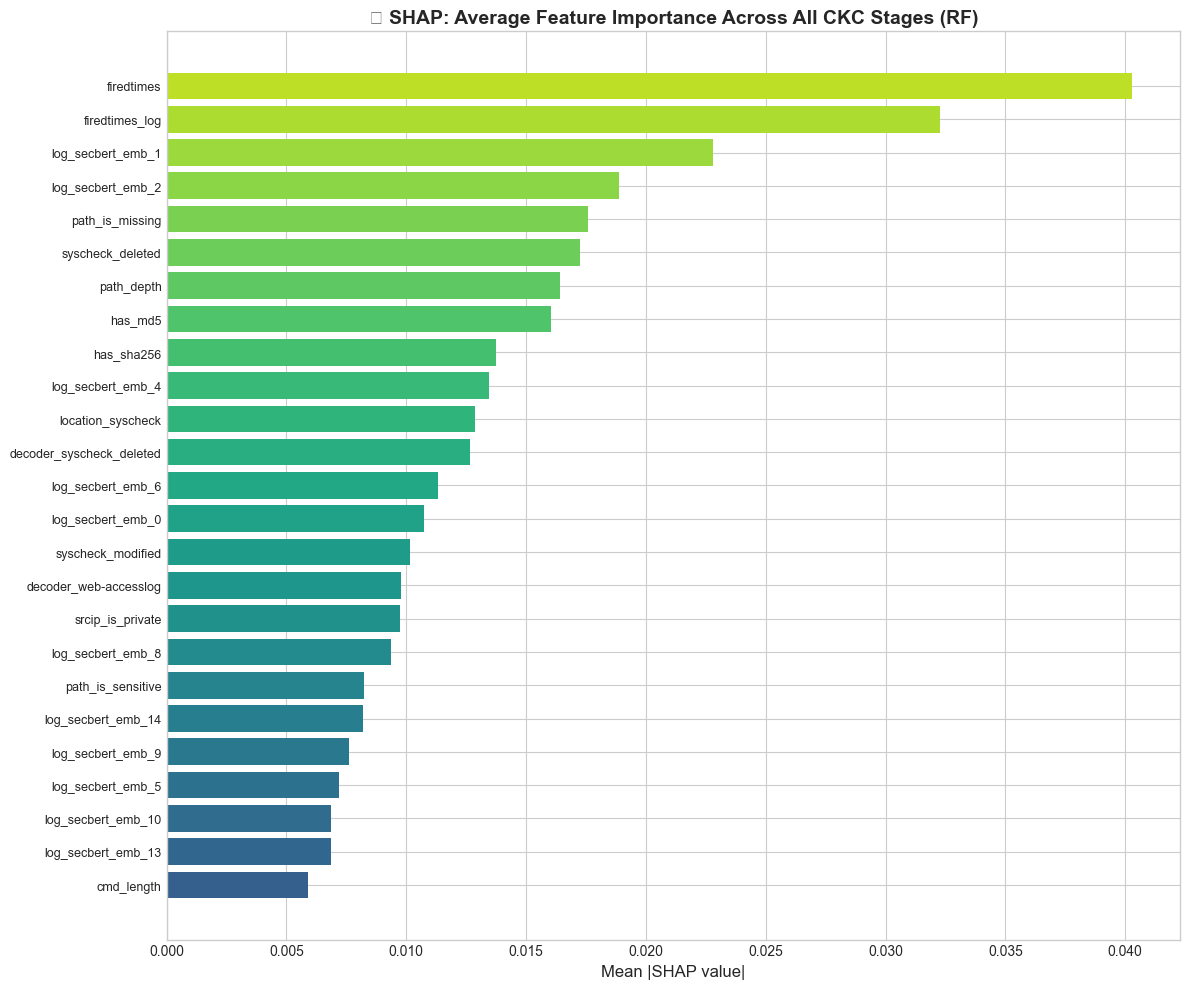


📊 Top 20 Features by SHAP (CKC Stages):
                 Feature  SHAP_Importance
              firedtimes         0.040272
          firedtimes_log         0.032266
       log_secbert_emb_1         0.022807
       log_secbert_emb_2         0.018867
         path_is_missing         0.017581
        syscheck_deleted         0.017240
              path_depth         0.016417
                 has_md5         0.016035
              has_sha256         0.013743
       log_secbert_emb_4         0.013465
       location_syscheck         0.012875
decoder_syscheck_deleted         0.012651
       log_secbert_emb_6         0.011328
       log_secbert_emb_0         0.010742
       syscheck_modified         0.010138
   decoder_web-accesslog         0.009798
        srcip_is_private         0.009742
       log_secbert_emb_8         0.009346
       path_is_sensitive         0.008243
      log_secbert_emb_14         0.008214


In [23]:
# SHAP Analysis for CKC Stage Classification (using RF due to SHAP/XGB compat issue)
print("🎨 Computing SHAP values for CKC Stage Classification (Random Forest)...")
print("   (This shows which features are important for EACH CKC stage)")

# Sample data if too large
sample_size = min(1500, len(X_test_ckc))
X_sample_ckc = X_test_ckc.sample(n=sample_size, random_state=42)

# Create SHAP explainer
explainer_ckc = shap.TreeExplainer(rf_ckc)
shap_values_ckc = explainer_ckc.shap_values(X_sample_ckc)

print(f"✅ SHAP values computed for {sample_size} samples!")

# For multi-class RF, shap_values is a list of arrays (one per class)
if isinstance(shap_values_ckc, list):
    shap_abs_mean = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values_ckc], axis=0)
else:
    shap_abs_mean = np.abs(shap_values_ckc).mean(axis=(0, 2)) if shap_values_ckc.ndim == 3 else np.abs(shap_values_ckc).mean(axis=0)

# Create importance dataframe
shap_importance_ckc = pd.DataFrame({
    'Feature': X_sample_ckc.columns,
    'SHAP_Importance': shap_abs_mean
}).sort_values('SHAP_Importance', ascending=False)

# Plot using matplotlib instead of shap's built-in
fig, ax = plt.subplots(figsize=(12, 10))
top_n = 25
top_shap = shap_importance_ckc.head(top_n)
ax.barh(range(top_n), top_shap['SHAP_Importance'].values[::-1], color=plt.cm.viridis(np.linspace(0.3, 0.9, top_n)))
ax.set_yticks(range(top_n))
ax.set_yticklabels(top_shap['Feature'].values[::-1], fontsize=9)
ax.set_xlabel('Mean |SHAP value|', fontsize=12)
ax.set_title("🎨 SHAP: Average Feature Importance Across All CKC Stages (RF)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\n📊 Top 20 Features by SHAP (CKC Stages):")
print(shap_importance_ckc.head(20).to_string(index=False))

📊 Per-Class Feature Importance for each CKC Stage:

🔹 S1:
          Feature  SHAP_Importance
log_secbert_emb_1         0.041445
log_secbert_emb_2         0.038877
       firedtimes         0.023903
   firedtimes_log         0.020420
log_secbert_emb_6         0.018980

🔹 S3:
          Feature  SHAP_Importance
       firedtimes         0.097442
   firedtimes_log         0.077346
log_secbert_emb_2         0.028733
log_secbert_emb_1         0.025367
       path_depth         0.021414

🔹 S4:
          Feature  SHAP_Importance
       firedtimes         0.075848
   firedtimes_log         0.060455
log_secbert_emb_1         0.022552
log_secbert_emb_2         0.016786
  path_is_missing         0.015776

🔹 S5:
                 Feature  SHAP_Importance
        syscheck_deleted         0.043099
decoder_syscheck_deleted         0.031628
       log_secbert_emb_4         0.025880
              path_depth         0.024185
         path_is_missing         0.016994

🔹 S7:
          Feature  SHAP_Importan

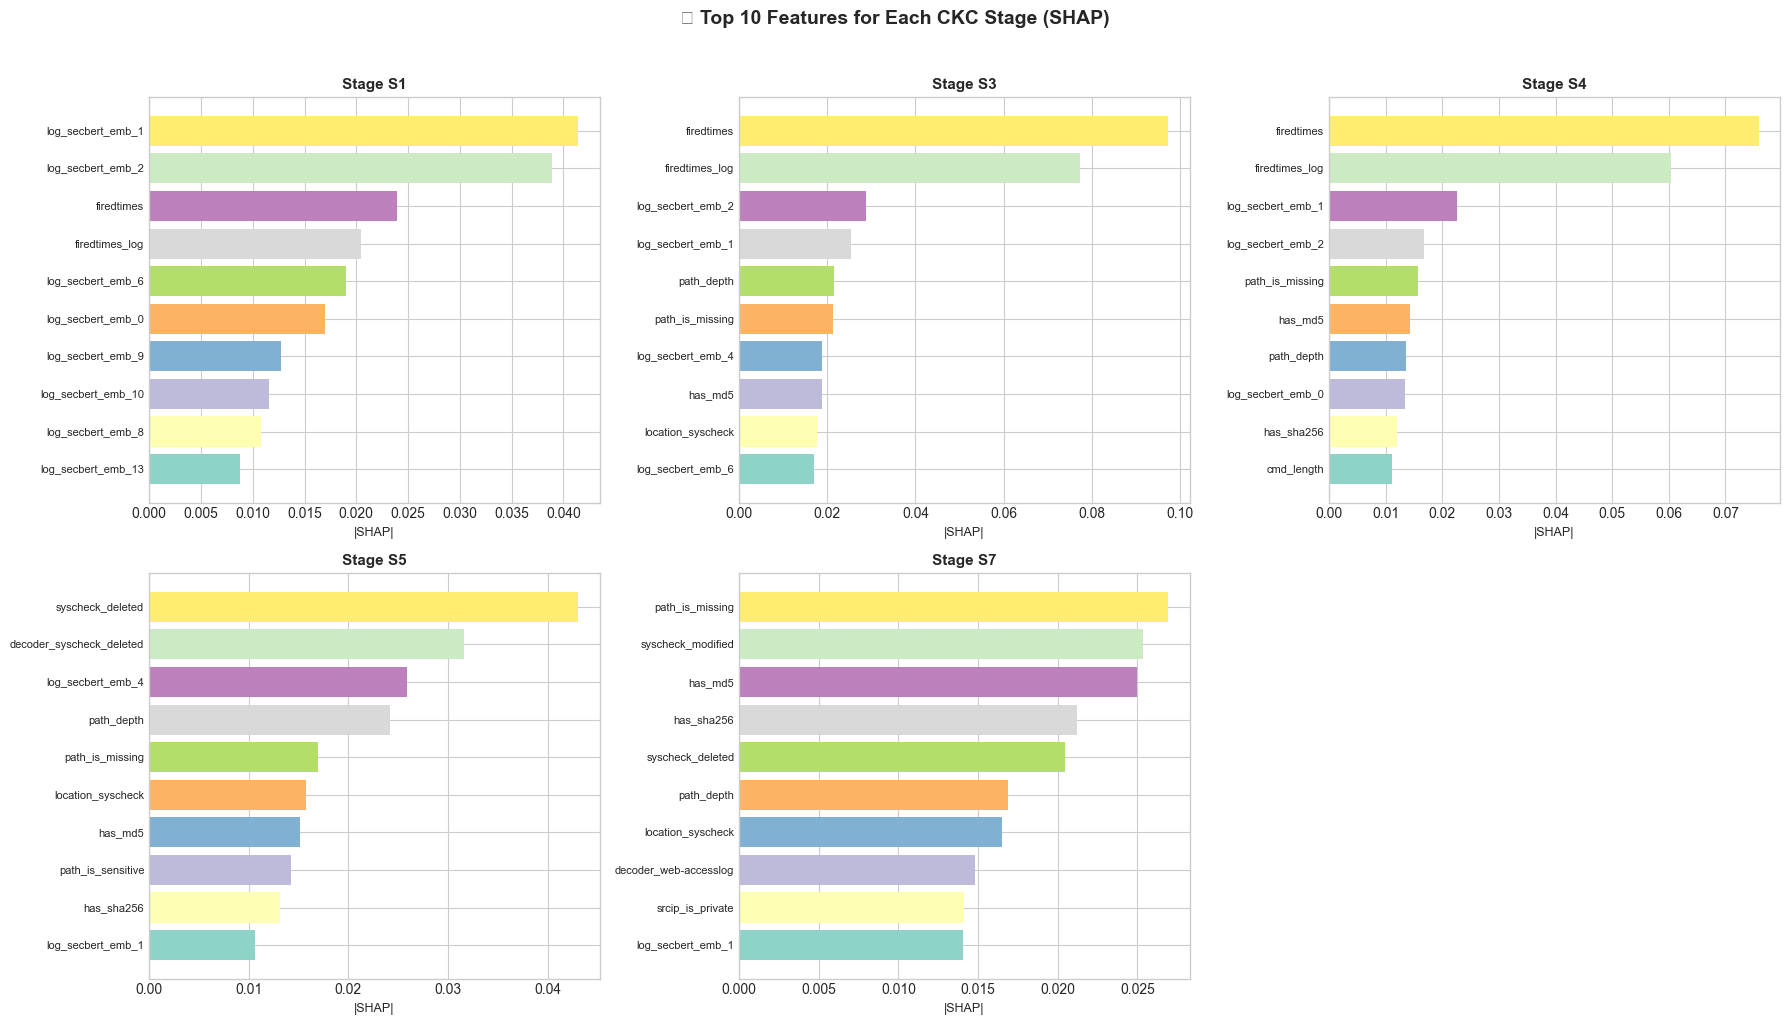

In [24]:
# Per-class SHAP analysis - show important features for each CKC stage
print("📊 Per-Class Feature Importance for each CKC Stage:")
print("="*70)

n_classes = len(ckc_label_encoder.classes_)

# Handle different SHAP value formats
if isinstance(shap_values_ckc, list):
    # List format - one array per class
    class_shap_arrays = shap_values_ckc
elif shap_values_ckc.ndim == 3:
    # 3D array (samples, features, classes)
    class_shap_arrays = [shap_values_ckc[:, :, i] for i in range(n_classes)]
else:
    # 2D array - use same values for each class
    class_shap_arrays = [shap_values_ckc for _ in range(n_classes)]

# Create subplots
n_cols = min(3, n_classes)
n_rows = (n_classes + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 5*n_rows))
if n_classes == 1:
    axes = np.array([[axes]])
elif n_rows == 1:
    axes = axes.reshape(1, -1)

class_importance_dict = {}

for i, cls_name in enumerate(ckc_label_encoder.classes_):
    row, col = i // n_cols, i % n_cols
    ax = axes[row, col]
    
    # Get mean absolute SHAP values for this class
    if i < len(class_shap_arrays):
        class_shap = np.abs(class_shap_arrays[i]).mean(axis=0)
    else:
        class_shap = np.zeros(len(X_sample_ckc.columns))
    
    class_df = pd.DataFrame({
        'Feature': X_sample_ckc.columns,
        'SHAP_Importance': class_shap
    }).sort_values('SHAP_Importance', ascending=False)
    
    class_importance_dict[cls_name] = class_df
    
    # Plot top features for this class
    top_10 = class_df.head(10)
    colors = plt.cm.Set3(np.linspace(0, 1, 10))
    ax.barh(range(10), top_10['SHAP_Importance'].values[::-1], color=colors)
    ax.set_yticks(range(10))
    ax.set_yticklabels(top_10['Feature'].values[::-1], fontsize=8)
    ax.set_title(f'Stage {cls_name}', fontsize=11, fontweight='bold')
    ax.set_xlabel('|SHAP|', fontsize=9)
    
    print(f"\n🔹 {cls_name}:")
    print(class_df.head(5).to_string(index=False))

# Hide unused subplots
for i in range(n_classes, n_rows * n_cols):
    row, col = i // n_cols, i % n_cols
    axes[row, col].axis('off')

plt.suptitle('🔗 Top 10 Features for Each CKC Stage (SHAP)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 📊 B.6 Combined Feature Ranking for CKC Stage Classification

📊 Creating Combined Feature Ranking for CKC STAGE Classification...

🏆 TOP 30 FEATURES FOR CKC STAGE CLASSIFICATION (Consensus Ranking)
                           Feature       RF      XGB      LGB  Average_Score
                        firedtimes 1.000000 0.014799 1.000000       0.671600
                 log_secbert_emb_1 0.963464 0.007922 0.464224       0.478537
                 syscheck_modified 0.374956 1.000000 0.016093       0.463683
                 log_secbert_emb_2 0.934677 0.017793 0.349839       0.434103
                  syscheck_deleted 0.661817 0.470279 0.026492       0.386196
                 log_secbert_emb_4 0.721958 0.012517 0.293389       0.342621
                 log_secbert_emb_0 0.534375 0.008617 0.386729       0.309907
                 log_secbert_emb_8 0.598525 0.001776 0.248329       0.282876
                    firedtimes_log 0.814475 0.000000 0.000000       0.271492
                 log_secbert_emb_6 0.526767 0.008775 0.273583       0.269708
                 

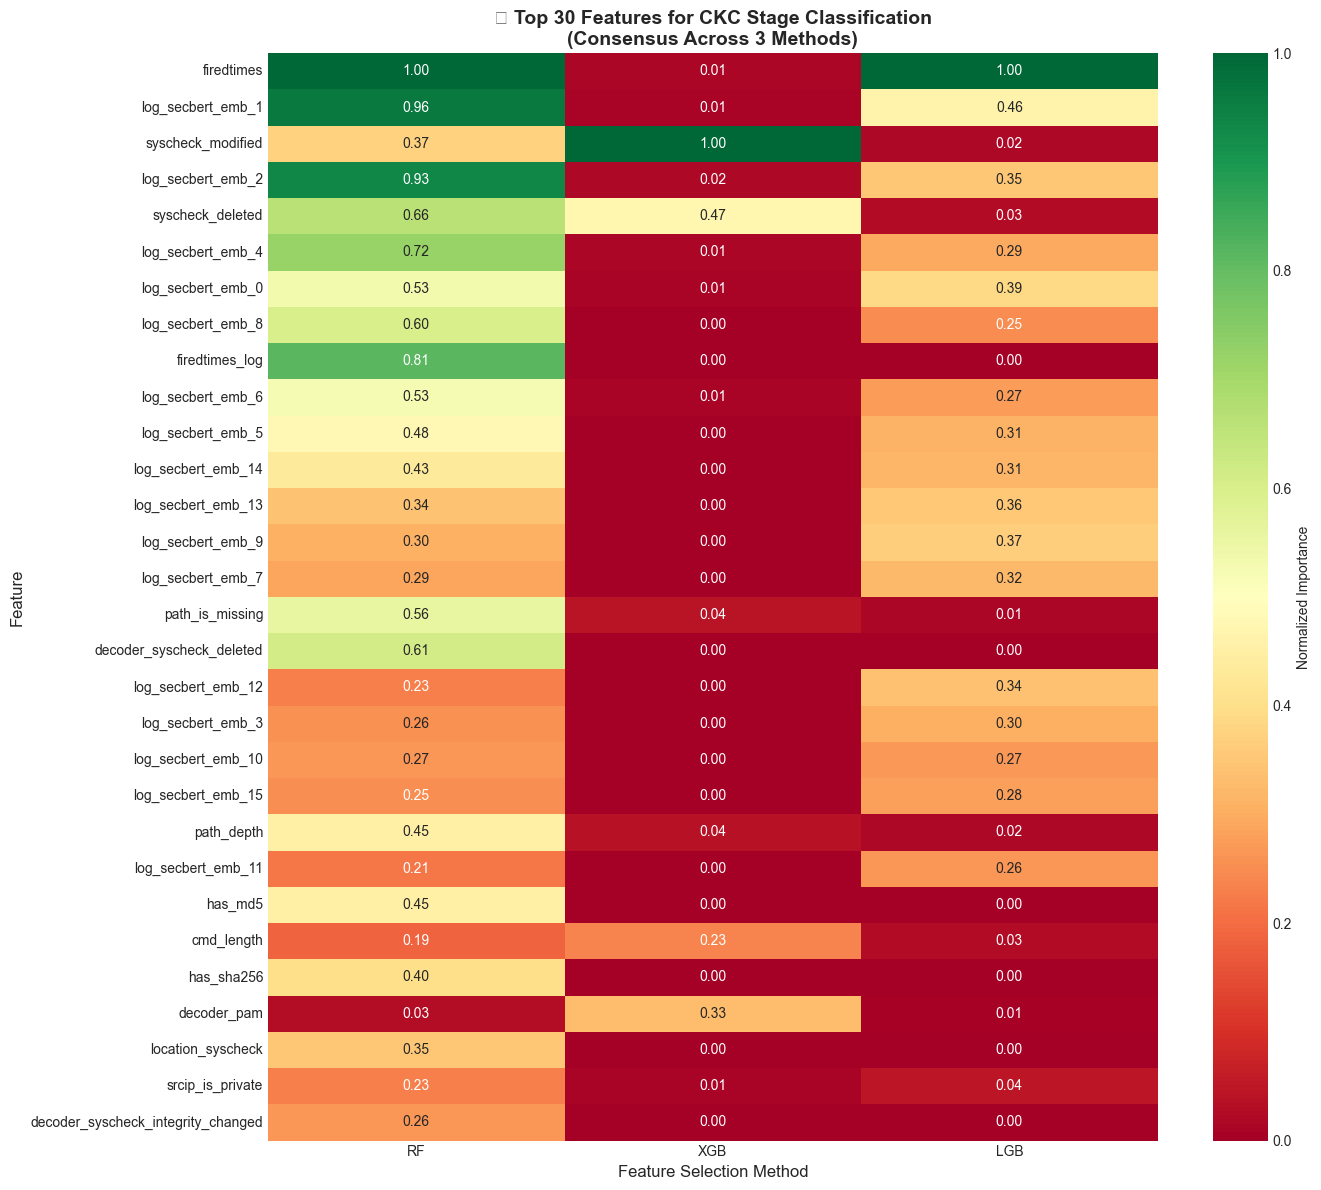

In [25]:
# Combine all CKC importance rankings
print("📊 Creating Combined Feature Ranking for CKC STAGE Classification...")

# Create combined dataframe
combined_ckc = pd.DataFrame({'Feature': X_ckc.columns})

# Add normalized scores
combined_ckc['RF'] = normalize(rf_importance_ckc.set_index('Feature').loc[X_ckc.columns, 'Importance'].values)
combined_ckc['XGB'] = normalize(xgb_importance_ckc.set_index('Feature').loc[X_ckc.columns, 'Importance'].values)
combined_ckc['LGB'] = normalize(lgb_importance_ckc.set_index('Feature').loc[X_ckc.columns, 'Importance'].values)

# Calculate average score
combined_ckc['Average_Score'] = combined_ckc[['RF', 'XGB', 'LGB']].mean(axis=1)
combined_ckc = combined_ckc.sort_values('Average_Score', ascending=False)

print("\n" + "="*100)
print("🏆 TOP 30 FEATURES FOR CKC STAGE CLASSIFICATION (Consensus Ranking)")
print("="*100)
print(combined_ckc.head(30).to_string(index=False))

# Visualize
fig, ax = plt.subplots(figsize=(14, 12))
top_n = 30
top_features_ckc = combined_ckc.head(top_n)

heatmap_data_ckc = top_features_ckc.set_index('Feature')[['RF', 'XGB', 'LGB']]
sns.heatmap(heatmap_data_ckc, annot=True, fmt='.2f', cmap='RdYlGn', ax=ax,
            cbar_kws={'label': 'Normalized Importance'})
ax.set_title('🏆 Top 30 Features for CKC Stage Classification\n(Consensus Across 3 Methods)', 
             fontsize=14, fontweight='bold')
ax.set_xlabel('Feature Selection Method', fontsize=12)
ax.set_ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

---
# 📋 PART C: FINAL SUMMARY & COMPARISON

## Comparison of Important Features for Both Tasks

In [26]:
# Final Summary - Compare top features for both tasks
print("="*100)
print("📋 FINAL SUMMARY: FEATURE IMPORTANCE FOR APT ATTACK DETECTION")
print("="*100)

# Top features for each task
n_top = 15
top_mal_features = combined_mal.head(n_top)['Feature'].tolist()
top_ckc_features = combined_ckc.head(n_top)['Feature'].tolist()

# Find common features
common_features = set(top_mal_features) & set(top_ckc_features)
unique_mal = set(top_mal_features) - set(top_ckc_features)
unique_ckc = set(top_ckc_features) - set(top_mal_features)

print("\n" + "="*100)
print(f"🎯 TOP {n_top} FEATURES FOR MALICIOUS DETECTION:")
print("="*100)
for i, feat in enumerate(top_mal_features, 1):
    score = combined_mal[combined_mal['Feature'] == feat]['Average_Score'].values[0]
    marker = "⭐" if feat in common_features else "  "
    print(f"   {marker} {i:2d}. {feat:<45} (Score: {score:.4f})")

print("\n" + "="*100)
print(f"🔗 TOP {n_top} FEATURES FOR CKC STAGE CLASSIFICATION:")
print("="*100)
for i, feat in enumerate(top_ckc_features, 1):
    score = combined_ckc[combined_ckc['Feature'] == feat]['Average_Score'].values[0]
    marker = "⭐" if feat in common_features else "  "
    print(f"   {marker} {i:2d}. {feat:<45} (Score: {score:.4f})")

print("\n" + "="*100)
print("🔄 ANALYSIS:")
print("="*100)
print(f"   ⭐ Features important for BOTH tasks: {len(common_features)}")
if common_features:
    for feat in common_features:
        print(f"      → {feat}")
        
print(f"\n   🔴 Features unique to MALICIOUS detection: {len(unique_mal)}")
for feat in list(unique_mal)[:5]:
    print(f"      → {feat}")
    
print(f"\n   🔵 Features unique to CKC STAGE classification: {len(unique_ckc)}")
for feat in list(unique_ckc)[:5]:
    print(f"      → {feat}")

📋 FINAL SUMMARY: FEATURE IMPORTANCE FOR APT ATTACK DETECTION

🎯 TOP 15 FEATURES FOR MALICIOUS DETECTION:
   ⭐  1. log_secbert_emb_1                             (Score: 0.5834)
       2. decoder_auditd                                (Score: 0.5362)
   ⭐  3. log_secbert_emb_0                             (Score: 0.5150)
   ⭐  4. firedtimes                                    (Score: 0.3577)
   ⭐  5. log_secbert_emb_2                             (Score: 0.2967)
       6. location__var_log_audit_audit.log             (Score: 0.2681)
   ⭐  7. log_secbert_emb_4                             (Score: 0.1733)
       8. srcip_is_private                              (Score: 0.1713)
   ⭐  9. log_secbert_emb_7                             (Score: 0.1687)
      10. log_secbert_emb_15                            (Score: 0.1681)
      11. decoder_web-accesslog                         (Score: 0.1595)
      12. location__var_log_apache2_access.log          (Score: 0.1580)
      13. log_secbert_emb_3          

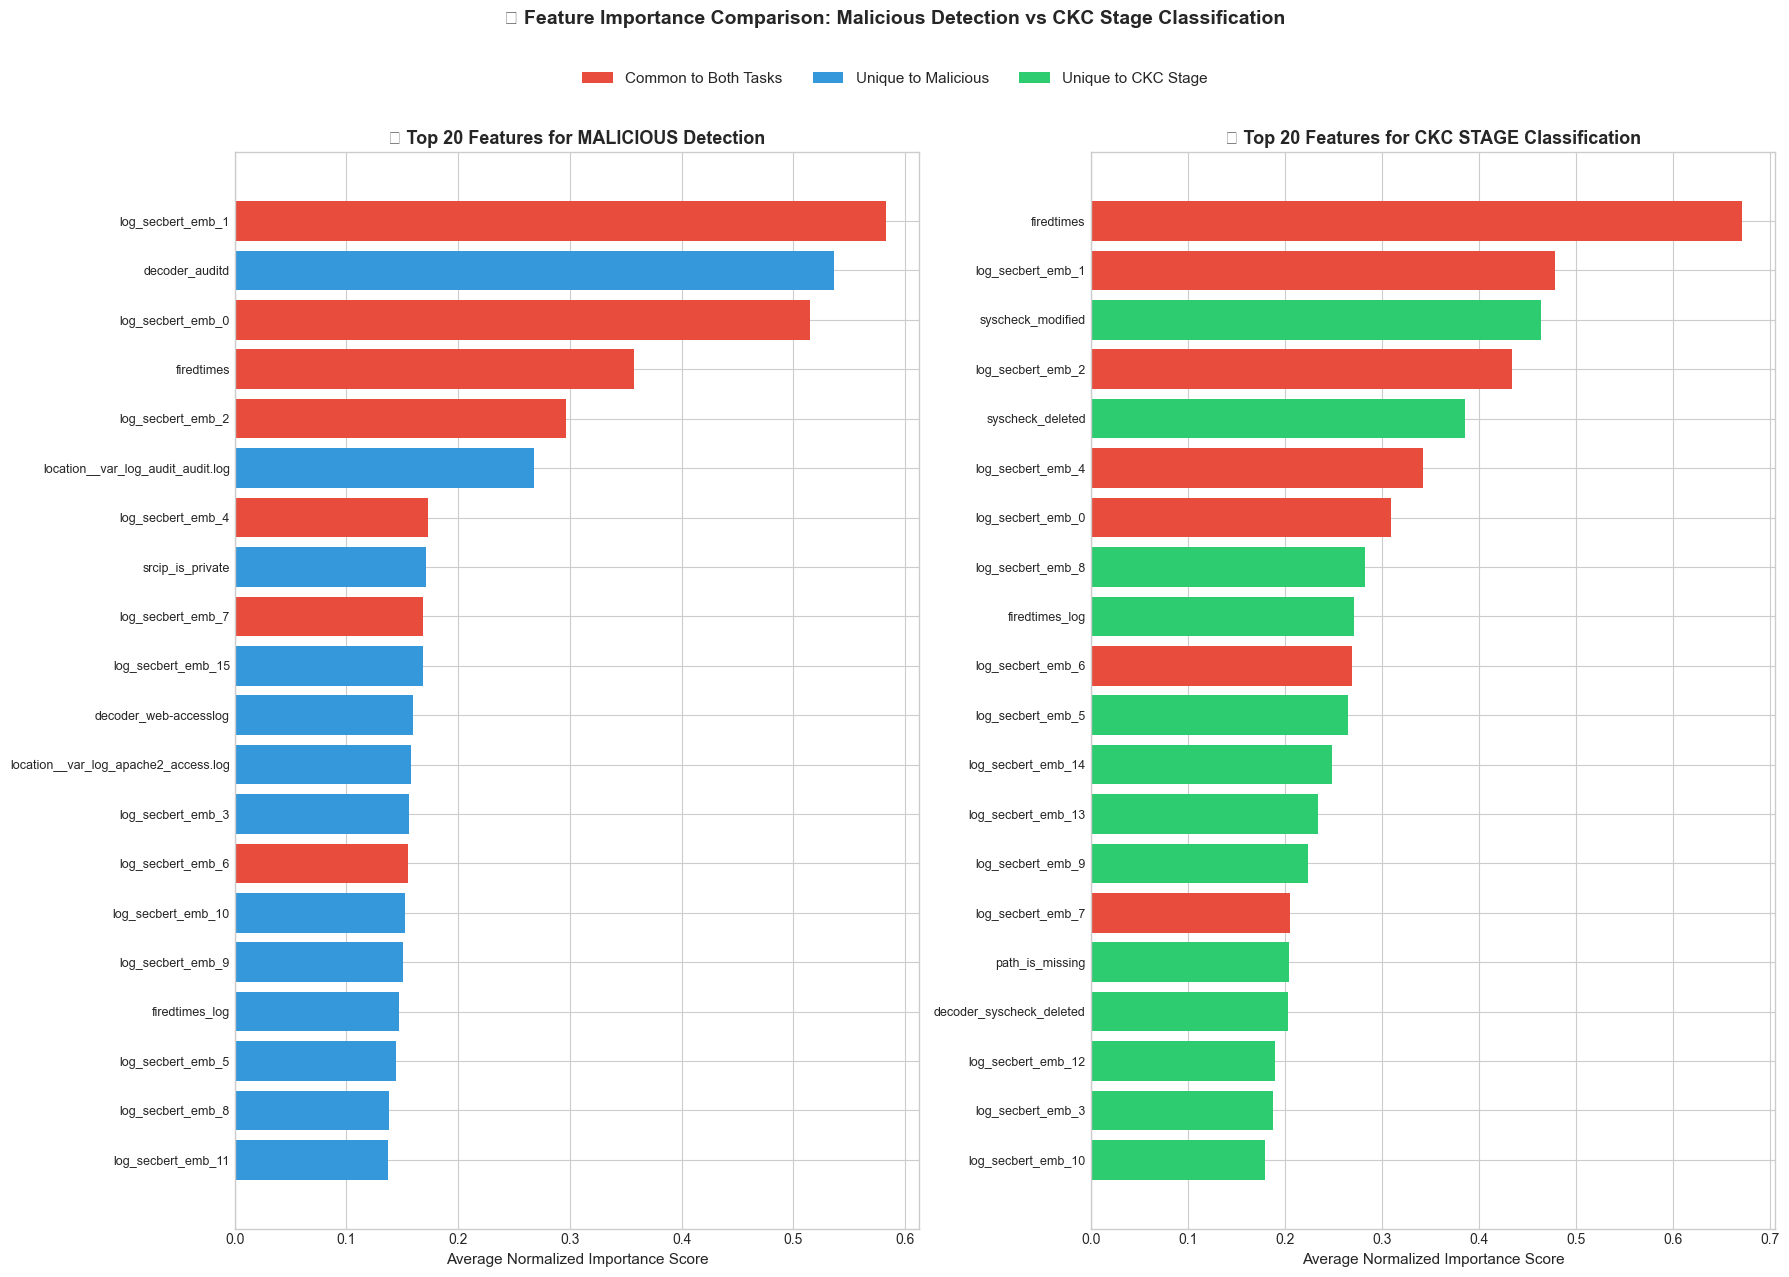

In [27]:
# Visualize comparison of feature importance between both tasks
fig, axes = plt.subplots(1, 2, figsize=(18, 12))

# Plot 1: Top features for Malicious detection
top_n_viz = 20
ax1 = axes[0]
top_mal = combined_mal.head(top_n_viz)
colors_mal = ['#e74c3c' if f in common_features else '#3498db' for f in top_mal['Feature']]
ax1.barh(range(top_n_viz), top_mal['Average_Score'].values[::-1], color=colors_mal[::-1])
ax1.set_yticks(range(top_n_viz))
ax1.set_yticklabels(top_mal['Feature'].values[::-1], fontsize=9)
ax1.set_xlabel('Average Normalized Importance Score', fontsize=11)
ax1.set_title(f'🔴 Top {top_n_viz} Features for MALICIOUS Detection', fontsize=13, fontweight='bold')
ax1.axvline(x=0, color='gray', linestyle='--', alpha=0.5)

# Plot 2: Top features for CKC Stage
ax2 = axes[1]
top_ckc = combined_ckc.head(top_n_viz)
colors_ckc = ['#e74c3c' if f in common_features else '#2ecc71' for f in top_ckc['Feature']]
ax2.barh(range(top_n_viz), top_ckc['Average_Score'].values[::-1], color=colors_ckc[::-1])
ax2.set_yticks(range(top_n_viz))
ax2.set_yticklabels(top_ckc['Feature'].values[::-1], fontsize=9)
ax2.set_xlabel('Average Normalized Importance Score', fontsize=11)
ax2.set_title(f'🔵 Top {top_n_viz} Features for CKC STAGE Classification', fontsize=13, fontweight='bold')
ax2.axvline(x=0, color='gray', linestyle='--', alpha=0.5)

# Add legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#e74c3c', label='Common to Both Tasks'),
    Patch(facecolor='#3498db', label='Unique to Malicious'),
    Patch(facecolor='#2ecc71', label='Unique to CKC Stage')
]
fig.legend(handles=legend_elements, loc='upper center', ncol=3, fontsize=11, bbox_to_anchor=(0.5, 1.02))

plt.suptitle('📊 Feature Importance Comparison: Malicious Detection vs CKC Stage Classification', 
             fontsize=14, fontweight='bold', y=1.06)
plt.tight_layout()
plt.show()

In [28]:
# Model Performance Summary
print("="*100)
print("📈 MODEL PERFORMANCE SUMMARY")
print("="*100)

print("\n🎯 MALICIOUS DETECTION (Binary Classification):")
print("-"*50)
print(f"   Random Forest Accuracy:  {rf_accuracy*100:.2f}%")
print(f"   XGBoost Accuracy:        {xgb_accuracy*100:.2f}%")
print(f"   LightGBM Accuracy:       {lgb_accuracy*100:.2f}%")
print(f"   Best Model:              {'XGBoost' if xgb_accuracy >= max(rf_accuracy, lgb_accuracy) else 'Random Forest' if rf_accuracy >= lgb_accuracy else 'LightGBM'}")

print("\n🔗 CKC STAGE CLASSIFICATION (Multi-class):")
print("-"*50)
print(f"   Random Forest Accuracy:  {rf_accuracy_ckc*100:.2f}%")
print(f"   XGBoost Accuracy:        {xgb_accuracy_ckc*100:.2f}%")
print(f"   LightGBM Accuracy:       {lgb_accuracy_ckc*100:.2f}%")
print(f"   Best Model:              {'XGBoost' if xgb_accuracy_ckc >= max(rf_accuracy_ckc, lgb_accuracy_ckc) else 'Random Forest' if rf_accuracy_ckc >= lgb_accuracy_ckc else 'LightGBM'}")
print(f"   Number of Classes:       {len(ckc_label_encoder.classes_)}")

📈 MODEL PERFORMANCE SUMMARY

🎯 MALICIOUS DETECTION (Binary Classification):
--------------------------------------------------
   Random Forest Accuracy:  99.39%
   XGBoost Accuracy:        99.70%
   LightGBM Accuracy:       99.65%
   Best Model:              XGBoost

🔗 CKC STAGE CLASSIFICATION (Multi-class):
--------------------------------------------------
   Random Forest Accuracy:  93.87%
   XGBoost Accuracy:        98.25%
   LightGBM Accuracy:       98.27%
   Best Model:              LightGBM
   Number of Classes:       5


In [29]:
# Save results to files
print("💾 Saving results to files...")

output_dir = r"c:\Users\KassoussiOussama-PFE\Downloads\pfe\feature_selection_outputs"
import os
os.makedirs(output_dir, exist_ok=True)

# Save combined rankings
combined_mal.to_csv(f"{output_dir}/feature_importance_malicious_detection.csv", index=False)
combined_ckc.to_csv(f"{output_dir}/feature_importance_ckc_stages.csv", index=False)

# Save per-model rankings for malicious detection
rf_importance_mal.to_csv(f"{output_dir}/rf_importance_malicious.csv", index=False)
xgb_importance_mal.to_csv(f"{output_dir}/xgb_importance_malicious.csv", index=False)
lgb_importance_mal.to_csv(f"{output_dir}/lgb_importance_malicious.csv", index=False)
perm_importance_mal.to_csv(f"{output_dir}/permutation_importance_malicious.csv", index=False)
mi_importance_mal.to_csv(f"{output_dir}/mutual_info_malicious.csv", index=False)

# Save per-model rankings for CKC
rf_importance_ckc.to_csv(f"{output_dir}/rf_importance_ckc.csv", index=False)
xgb_importance_ckc.to_csv(f"{output_dir}/xgb_importance_ckc.csv", index=False)
lgb_importance_ckc.to_csv(f"{output_dir}/lgb_importance_ckc.csv", index=False)

# Save summary
summary = {
    'task': ['Malicious Detection', 'Malicious Detection', 'Malicious Detection',
             'CKC Stage Classification', 'CKC Stage Classification', 'CKC Stage Classification'],
    'model': ['Random Forest', 'XGBoost', 'LightGBM', 'Random Forest', 'XGBoost', 'LightGBM'],
    'accuracy': [rf_accuracy, xgb_accuracy, lgb_accuracy, rf_accuracy_ckc, xgb_accuracy_ckc, lgb_accuracy_ckc],
    'version': ['V2_NoLeakage_SecBERT'] * 6
}
pd.DataFrame(summary).to_csv(f"{output_dir}/model_performance_summary.csv", index=False)

print(f"\n✅ All results saved to: {output_dir}")
print(f"   📄 feature_importance_malicious_detection.csv")
print(f"   📄 feature_importance_ckc_stages.csv")
print(f"   📄 model_performance_summary.csv")
print(f"   📄 Per-model importance files...")
print(f"\n📝 Version: V2 - No Data Leakage + SecBERT Embeddings")

💾 Saving results to files...

✅ All results saved to: c:\Users\KassoussiOussama-PFE\Downloads\pfe\feature_selection_outputs
   📄 feature_importance_malicious_detection.csv
   📄 feature_importance_ckc_stages.csv
   📄 model_performance_summary.csv
   📄 Per-model importance files...

📝 Version: V2 - No Data Leakage + SecBERT Embeddings


---
## 📝 Key Findings & Recommendations (V2 - No Leakage + SecBERT)

### ⚠️ Data Leakage Fix
Previous version used `rule_level` and derived severity features which are **indirect labels** for maliciousness.
This version excludes ALL leaky features following the AE notebook's approach:
- `rule_level`, `is_high_severity`, `is_critical_severity` (severity = indirect label)
- MITRE ATT&CK features (only exist for malicious alerts)
- `rule.description` text (contains attack keywords)

### 🤖 SecBERT Embeddings (NEW)
- Used **SecBERT** (cybersecurity-pretrained BERT) for semantic text embeddings
- Applied to `_source.data.command` (16 PCA components)
- Applied to `_source.full_log` (16 PCA components)
- These capture **semantic meaning** beyond simple keyword matching

### 1️⃣ Features for Malicious Detection (Is this alert malicious?)
With leakage fixed, the truly important features are **behavioral signals**:
- **Command patterns** - Suspicious commands (sudo, wget, nc, base64, etc.)
- **SecBERT embeddings** - Semantic understanding of commands and logs
- **Path characteristics** - Access to sensitive directories (/etc, /root, /tmp)
- **Temporal features** - Unusual time patterns (night, weekend activity)
- **Decoder/Location** - Which log source generated the alert

### 2️⃣ Features for CKC Stage Classification (What stage of attack?)
Different features help distinguish between kill chain stages:
- **Early stages (Reconnaissance/Delivery)**: Network-related features, discovery commands
- **Middle stages (Exploitation/Installation)**: Command execution patterns, file modifications
- **Late stages (C2/Actions)**: Persistence mechanisms, data access patterns

### 3️⃣ Recommendations for APT Detection System
1. **Use the top consensus features** from both analyses for your models
2. **Monitor high-importance features** in real-time for early detection
3. **SecBERT embeddings** provide richer representations than keyword matching
4. **Consider feature engineering** to create more discriminative features based on insights

---
*Analysis completed with full data leakage prevention and SecBERT text embeddings.*

---
## 📖 Feature Name Mapping: Engineered Features → Original Dataset Columns

This section explains what each engineered feature represents in terms of the original columns in the dataset.

In [30]:
# Complete Feature Mapping: Engineered Feature Name → Original Dataset Column
# V2: Excludes leaky features, includes SecBERT embeddings

feature_mapping = {
    # ═══════════════════════════════════════════════════════════════════════════
    # TEMPORAL FEATURES (from _source.@timestamp)
    # ═══════════════════════════════════════════════════════════════════════════
    'hour_of_day': {
        'original_column': '_source.@timestamp',
        'description': 'Hour of the day (0-23) when the alert occurred',
        'type': 'Extracted from timestamp'
    },
    'day_of_week': {
        'original_column': '_source.@timestamp',
        'description': 'Day of the week (0=Monday, 6=Sunday)',
        'type': 'Extracted from timestamp'
    },
    'is_weekend': {
        'original_column': '_source.@timestamp',
        'description': '1 if alert occurred on Saturday/Sunday, 0 otherwise',
        'type': 'Derived binary flag'
    },
    'is_night': {
        'original_column': '_source.@timestamp',
        'description': '1 if alert occurred between 22:00-06:00, 0 otherwise',
        'type': 'Derived binary flag'
    },
    'is_business_hours': {
        'original_column': '_source.@timestamp',
        'description': '1 if alert occurred between 09:00-17:00, 0 otherwise',
        'type': 'Derived binary flag'
    },
    
    # ═══════════════════════════════════════════════════════════════════════════
    # ❌ EXCLUDED: rule_level, is_high_severity, is_critical_severity
    # Reason: Wazuh severity = indirect malicious label = DATA LEAKAGE
    # ═══════════════════════════════════════════════════════════════════════════
    
    # ═══════════════════════════════════════════════════════════════════════════
    # RULE FIRED TIMES (from _source.rule.firedtimes) - KEPT (behavioral)
    # ═══════════════════════════════════════════════════════════════════════════
    'firedtimes': {
        'original_column': '_source.rule.firedtimes',
        'description': 'Number of times this rule has been triggered',
        'type': 'Direct numeric value'
    },
    'firedtimes_log': {
        'original_column': '_source.rule.firedtimes',
        'description': 'Log-transformed firedtimes: log(1 + firedtimes)',
        'type': 'Log transformation'
    },
    
    # ═══════════════════════════════════════════════════════════════════════════
    # IP ADDRESS FEATURES
    # ═══════════════════════════════════════════════════════════════════════════
    'ip_is_private': {
        'original_column': '_source.agent.ip',
        'description': '1 if agent IP is private, 0 if public, -1 if missing',
        'type': 'Derived from IP parsing'
    },
    'ip_is_missing': {
        'original_column': '_source.agent.ip',
        'description': '1 if agent IP is missing/null',
        'type': 'Missing value indicator'
    },
    'srcip_is_private': {
        'original_column': '_source.data.srcip',
        'description': '1 if source IP is private, 0 if public, -1 if missing',
        'type': 'Derived from IP parsing'
    },
    'srcip_is_missing': {
        'original_column': '_source.data.srcip',
        'description': '1 if source IP is missing/null',
        'type': 'Missing value indicator'
    },
    
    # ═══════════════════════════════════════════════════════════════════════════
    # FILE PATH FEATURES (from _source.syscheck.path)
    # ═══════════════════════════════════════════════════════════════════════════
    'path_depth': {
        'original_column': '_source.syscheck.path',
        'description': 'Directory depth (count of / in path)',
        'type': 'Extracted from path'
    },
    'path_is_sensitive': {
        'original_column': '_source.syscheck.path',
        'description': '1 if path contains /etc, /root, /var/log, etc.',
        'type': 'Pattern matching'
    },
    'path_is_hidden': {
        'original_column': '_source.syscheck.path',
        'description': '1 if path contains hidden file/folder',
        'type': 'Pattern matching'
    },
    'path_is_suspicious_ext': {
        'original_column': '_source.syscheck.path',
        'description': '1 if file has suspicious extension (.sh, .py, .php, etc.)',
        'type': 'Pattern matching'
    },
    'path_is_temp': {
        'original_column': '_source.syscheck.path',
        'description': '1 if path is in /tmp or /temp directory',
        'type': 'Pattern matching'
    },
    'path_is_missing': {
        'original_column': '_source.syscheck.path',
        'description': '1 if syscheck path is missing/null',
        'type': 'Missing value indicator'
    },
    
    # ═══════════════════════════════════════════════════════════════════════════
    # COMMAND FEATURES - REGEX PATTERNS (from _source.data.command)
    # ═══════════════════════════════════════════════════════════════════════════
    'cmd_sudo_usage': {
        'original_column': '_source.data.command',
        'description': '1 if command contains "sudo"',
        'type': 'Regex pattern matching'
    },
    'cmd_wget_curl': {
        'original_column': '_source.data.command',
        'description': '1 if command contains "wget" or "curl"',
        'type': 'Regex pattern matching'
    },
    'cmd_nc_netcat': {
        'original_column': '_source.data.command',
        'description': '1 if command contains "nc", "netcat", or "ncat"',
        'type': 'Regex pattern matching'
    },
    'cmd_base64': {
        'original_column': '_source.data.command',
        'description': '1 if command contains "base64"',
        'type': 'Regex pattern matching'
    },
    'cmd_length': {
        'original_column': '_source.data.command',
        'description': 'Length of the command string in characters',
        'type': 'String length'
    },
    'cmd_is_missing': {
        'original_column': '_source.data.command',
        'description': '1 if command field is missing/null',
        'type': 'Missing value indicator'
    },
    
    # ═══════════════════════════════════════════════════════════════════════════
    # 🤖 SecBERT COMMAND EMBEDDINGS (NEW - from _source.data.command)
    # ═══════════════════════════════════════════════════════════════════════════
    'cmd_secbert_emb_0..15': {
        'original_column': '_source.data.command',
        'description': 'SecBERT semantic embedding components (PCA-reduced to 16 dims)',
        'type': 'SecBERT transformer + PCA'
    },
    
    # ═══════════════════════════════════════════════════════════════════════════
    # 🤖 SecBERT FULL LOG EMBEDDINGS (NEW - from _source.full_log)
    # ═══════════════════════════════════════════════════════════════════════════
    'log_secbert_emb_0..15': {
        'original_column': '_source.full_log',
        'description': 'SecBERT semantic embedding components (PCA-reduced to 16 dims)',
        'type': 'SecBERT transformer + PCA'
    },
    
    # ═══════════════════════════════════════════════════════════════════════════
    # ❌ EXCLUDED: ALL MITRE ATT&CK FEATURES
    # Reason: MITRE mappings only exist for malicious alerts = DATA LEAKAGE
    # ═══════════════════════════════════════════════════════════════════════════
    
    # ═══════════════════════════════════════════════════════════════════════════
    # FILE INTEGRITY (SYSCHECK) FEATURES
    # ═══════════════════════════════════════════════════════════════════════════
    'has_md5': {
        'original_column': '_source.syscheck.md5_after',
        'description': '1 if MD5 hash is present after file change',
        'type': 'Non-null indicator'
    },
    'has_sha256': {
        'original_column': '_source.syscheck.sha256_after',
        'description': '1 if SHA256 hash is present after file change',
        'type': 'Non-null indicator'
    },
    'syscheck_added': {
        'original_column': '_source.syscheck.event',
        'description': '1 if syscheck event type is "added"',
        'type': 'Category indicator'
    },
    'syscheck_modified': {
        'original_column': '_source.syscheck.event',
        'description': '1 if syscheck event type is "modified"',
        'type': 'Category indicator'
    },
    'syscheck_deleted': {
        'original_column': '_source.syscheck.event',
        'description': '1 if syscheck event type is "deleted"',
        'type': 'Category indicator'
    },
    
    # ═══════════════════════════════════════════════════════════════════════════
    # CHANGED ATTRIBUTES (from _source.syscheck.changed_attributes)
    # ═══════════════════════════════════════════════════════════════════════════
    'changed_size': {
        'original_column': '_source.syscheck.changed_attributes',
        'description': '1 if file size changed',
        'type': 'Attribute flag'
    },
    'changed_permission': {
        'original_column': '_source.syscheck.changed_attributes',
        'description': '1 if file permissions changed',
        'type': 'Attribute flag'
    },
    
    # ═══════════════════════════════════════════════════════════════════════════
    # PORT FEATURES (from _source.data.srcport)
    # ═══════════════════════════════════════════════════════════════════════════
    'srcport': {
        'original_column': '_source.data.srcport',
        'description': 'Source port number',
        'type': 'Direct numeric value'
    },
    'is_privileged_port': {
        'original_column': '_source.data.srcport',
        'description': '1 if port < 1024 (privileged/well-known)',
        'type': 'Derived binary flag'
    },
    'is_high_port': {
        'original_column': '_source.data.srcport',
        'description': '1 if port > 49152 (dynamic/ephemeral)',
        'type': 'Derived binary flag'
    },
    
    # ═══════════════════════════════════════════════════════════════════════════
    # DECODER FEATURES (One-hot from _source.decoder.name)
    # ═══════════════════════════════════════════════════════════════════════════
    'decoder_*': {
        'original_column': '_source.decoder.name',
        'description': 'One-hot encoded top-15 decoder names',
        'type': 'One-hot encoded category'
    },
    
    # ═══════════════════════════════════════════════════════════════════════════
    # LOCATION FEATURES (One-hot from _source.location)
    # ═══════════════════════════════════════════════════════════════════════════
    'location_*': {
        'original_column': '_source.location',
        'description': 'One-hot encoded top-15 log source locations',
        'type': 'One-hot encoded category'
    },
}

# Display the mapping as a formatted table
print("="*120)
print("📖 FEATURE NAME MAPPING V2: Engineered Feature → Original Dataset Column")
print("   (Leaky features EXCLUDED, SecBERT embeddings ADDED)")
print("="*120)

# Group features by original column
from collections import defaultdict
grouped = defaultdict(list)
for feat, info in feature_mapping.items():
    grouped[info['original_column']].append((feat, info['description'], info['type']))

for original_col, features in grouped.items():
    print(f"\n🔹 Original Column: {original_col}")
    print("-"*100)
    for feat_name, desc, feat_type in features:
        print(f"   → {feat_name:<45} | {feat_type:<25} | {desc[:55]}")

print("\n" + "="*120)
print("❌ EXCLUDED FEATURES (Data Leakage):")
print("   → rule_level, is_high_severity, is_critical_severity (from _source.rule.level)")
print("   → tactic_*, technique_count, has_mitre_* (from _source.rule.mitre_*)")
print("   → rule.description text features (contains attack keywords)")
print("="*120)

📖 FEATURE NAME MAPPING V2: Engineered Feature → Original Dataset Column
   (Leaky features EXCLUDED, SecBERT embeddings ADDED)

🔹 Original Column: _source.@timestamp
----------------------------------------------------------------------------------------------------
   → hour_of_day                                   | Extracted from timestamp  | Hour of the day (0-23) when the alert occurred
   → day_of_week                                   | Extracted from timestamp  | Day of the week (0=Monday, 6=Sunday)
   → is_weekend                                    | Derived binary flag       | 1 if alert occurred on Saturday/Sunday, 0 otherwise
   → is_night                                      | Derived binary flag       | 1 if alert occurred between 22:00-06:00, 0 otherwise
   → is_business_hours                             | Derived binary flag       | 1 if alert occurred between 09:00-17:00, 0 otherwise

🔹 Original Column: _source.rule.firedtimes
------------------------------------------

In [31]:
# Create a clean summary table for the TOP important features
print("\n" + "="*120)
print("📊 TOP IMPORTANT FEATURES - QUICK REFERENCE (V2 - No Leakage + SecBERT)")
print("="*120)

top_features_explanation = {
    # Behavioral features (no leakage)
    'decoder_auditd': ('_source.decoder.name', 'Alert from Linux audit daemon - tracks system calls'),
    'location__var_log_audit_audit.log': ('_source.location', 'Alert source is audit log file'),
    'location__var_log_auth.log': ('_source.location', 'Alert source is authentication log file'),
    'firedtimes': ('_source.rule.firedtimes', 'How many times this rule triggered'),
    'srcip_is_private': ('_source.data.srcip', 'Is source IP internal (1) or external (0)?'),
    'decoder_web-accesslog': ('_source.decoder.name', 'Alert from web server access logs'),
    'cmd_length': ('_source.data.command', 'Length of command string - longer may indicate obfuscation'),
    'has_md5': ('_source.syscheck.md5_after', 'File has MD5 hash (file integrity event)'),
    'has_sha256': ('_source.syscheck.sha256_after', 'File has SHA256 hash (file integrity event)'),
    'syscheck_modified': ('_source.syscheck.event', 'File was modified (Installation/Actions stage)'),
    'syscheck_deleted': ('_source.syscheck.event', 'File was deleted (Defense evasion/Actions stage)'),
    'firedtimes_log': ('_source.rule.firedtimes', 'Log of firedtimes - normalizes large values'),
    'path_is_missing': ('_source.syscheck.path', 'No file path in alert (non-file event)'),
    'path_depth': ('_source.syscheck.path', 'Directory depth - deeper paths may be suspicious'),
    'path_is_sensitive': ('_source.syscheck.path', 'File in sensitive directory (/etc, /root, etc.)'),
    # SecBERT features
    'cmd_secbert_emb_*': ('_source.data.command', 'SecBERT semantic embedding of command text'),
    'log_secbert_emb_*': ('_source.full_log', 'SecBERT semantic embedding of full log text'),
}

print("\n🎯 FEATURES FOR MALICIOUS DETECTION (V2 - Leakage-Free):")
print("-"*100)
print(f"{'Feature Name':<45} {'Original Column':<40} {'Meaning'}")
print("-"*100)
for feat in ['decoder_auditd', 'location__var_log_audit_audit.log', 
             'location__var_log_auth.log', 'firedtimes', 'srcip_is_private', 
             'decoder_web-accesslog', 'cmd_length', 'has_md5', 'has_sha256',
             'cmd_secbert_emb_*', 'log_secbert_emb_*']:
    if feat in top_features_explanation:
        col, meaning = top_features_explanation[feat]
        print(f"{feat:<45} {col:<40} {meaning}")

print("\n\n🔗 FEATURES FOR CKC STAGE CLASSIFICATION:")
print("-"*100)
print(f"{'Feature Name':<45} {'Original Column':<40} {'Meaning'}")
print("-"*100)
for feat in ['firedtimes', 'syscheck_modified', 'syscheck_deleted',
             'firedtimes_log', 'path_is_missing', 'path_depth',
             'has_md5', 'has_sha256', 'cmd_secbert_emb_*', 'log_secbert_emb_*']:
    if feat in top_features_explanation:
        col, meaning = top_features_explanation[feat]
        print(f"{feat:<45} {col:<40} {meaning}")

print("\n" + "="*100)
print("❌ EXCLUDED (Data Leakage):")
print("   → rule_level (severity = indirect label)")
print("   → is_high_severity, is_critical_severity (derived from rule_level)")
print("   → MITRE features (only exist for malicious alerts)")
print("   → rule.description text (contains attack keywords)")
print("✅ ADDED:")
print("   → SecBERT command embeddings (16 dims) - semantic understanding")
print("   → SecBERT full_log embeddings (16 dims) - semantic understanding")
print("="*100)


📊 TOP IMPORTANT FEATURES - QUICK REFERENCE (V2 - No Leakage + SecBERT)

🎯 FEATURES FOR MALICIOUS DETECTION (V2 - Leakage-Free):
----------------------------------------------------------------------------------------------------
Feature Name                                  Original Column                          Meaning
----------------------------------------------------------------------------------------------------
decoder_auditd                                _source.decoder.name                     Alert from Linux audit daemon - tracks system calls
location__var_log_audit_audit.log             _source.location                         Alert source is audit log file
location__var_log_auth.log                    _source.location                         Alert source is authentication log file
firedtimes                                    _source.rule.firedtimes                  How many times this rule triggered
srcip_is_private                              _source.data.srcip    

In [32]:
# Save feature mapping to CSV for reference
mapping_df = pd.DataFrame([
    {
        'Engineered_Feature': feat,
        'Original_Column': info['original_column'],
        'Description': info['description'],
        'Type': info['type']
    }
    for feat, info in feature_mapping.items()
])

mapping_df.to_csv(f"{output_dir}/feature_mapping_reference.csv", index=False)
print(f"\n✅ Feature mapping saved to: {output_dir}/feature_mapping_reference.csv")

# Display as a nice table
print("\n📋 Complete Feature Mapping Table:")
mapping_df.head(30)


✅ Feature mapping saved to: c:\Users\KassoussiOussama-PFE\Downloads\pfe\feature_selection_outputs/feature_mapping_reference.csv

📋 Complete Feature Mapping Table:


,Engineered_Feature,Original_Column,Description,Type
0,hour_of_day,_source.@timestamp,Hour of the day (0-23) when the alert occurred,Extracted from timestamp
1,day_of_week,_source.@timestamp,"Day of the week (0=Monday, 6=Sunday)",Extracted from timestamp
2,is_weekend,_source.@timestamp,"1 if alert occurred on Saturday/Sunday, 0 otherwise",Derived binary flag
3,is_night,_source.@timestamp,"1 if alert occurred between 22:00-06:00, 0 otherwise",Derived binary flag
4,is_business_hours,_source.@timestamp,"1 if alert occurred between 09:00-17:00, 0 otherwise",Derived binary flag
5,firedtimes,_source.rule.firedtimes,Number of times this rule has been triggered,Direct numeric value
6,firedtimes_log,_source.rule.firedtimes,Log-transformed firedtimes: log(1 + firedtimes),Log transformation
7,ip_is_private,_source.agent.ip,"1 if agent IP is private, 0 if public, -1 if missing",Derived from IP parsing
8,ip_is_missing,_source.agent.ip,1 if agent IP is missing/null,Missing value indicator
9,srcip_is_private,_source.data.srcip,"1 if source IP is private, 0 if public, -1 if missing",Derived from IP parsing


In [33]:
# =============================================================================
# 🔍 EXPLORE ALL UNIQUE VALUES IN TEXT COLUMNS
# =============================================================================
# This shows what values exist vs what we capture

print("="*80)
print("🔍 WHAT VALUES EXIST IN TEXT COLUMNS?")
print("="*80)

# 1. Decoder names
print("\n📌 1. _source.decoder.name - ALL UNIQUE VALUES:")
print("-"*60)
if '_source.decoder.name' in df.columns:
    decoder_counts = df['_source.decoder.name'].value_counts()
    print(f"Total unique decoders: {len(decoder_counts)}")
    print(f"\n⚠️ We only encode TOP 15, missing {max(0, len(decoder_counts)-15)} decoders!\n")
    print(decoder_counts.to_string())
else:
    print("Column not found")

# 2. Locations
print("\n\n📌 2. _source.location - ALL UNIQUE VALUES:")
print("-"*60)
if '_source.location' in df.columns:
    location_counts = df['_source.location'].value_counts()
    print(f"Total unique locations: {len(location_counts)}")
    print(f"\n⚠️ We only encode TOP 15, missing {max(0, len(location_counts)-15)} locations!\n")
    print(location_counts.head(30).to_string())  # Show top 30
else:
    print("Column not found")

# 3. Commands (show samples)
print("\n\n📌 3. _source.data.command - SAMPLE VALUES:")
print("-"*60)
if '_source.data.command' in df.columns:
    cmd_sample = df['_source.data.command'].dropna().sample(min(20, len(df)), random_state=42)
    print(f"Total non-null commands: {df['_source.data.command'].notna().sum()}")
    print(f"\n⚠️ We only detect PRE-DEFINED patterns (sudo, wget, etc.)")
    print("⚠️ Unknown attack commands would be MISSED!\n")
    for i, cmd in enumerate(cmd_sample.values[:10], 1):
        print(f"{i}. {str(cmd)[:100]}...")
else:
    print("Column not found")

# 4. Summary of coverage
print("\n\n" + "="*80)
print("📊 ENCODING COVERAGE SUMMARY")
print("="*80)

coverage_data = []
for col in ['_source.decoder.name', '_source.location']:
    if col in df.columns:
        total_unique = df[col].nunique()
        encoded = min(15, total_unique)  # We encode top 15
        coverage = (encoded / total_unique) * 100 if total_unique > 0 else 0
        missed = total_unique - encoded
        coverage_data.append({
            'Column': col,
            'Total Unique': total_unique,
            'Encoded': encoded,
            'Missed': missed,
            'Coverage %': f"{coverage:.1f}%"
        })

print(pd.DataFrame(coverage_data).to_string(index=False))

🔍 WHAT VALUES EXIST IN TEXT COLUMNS?

📌 1. _source.decoder.name - ALL UNIQUE VALUES:
------------------------------------------------------------
Total unique decoders: 19

⚠️ We only encode TOP 15, missing 4 decoders!

_source.decoder.name
auditd                        77009
web-accesslog                 27280
pam                            2731
syscheck_integrity_changed     1624
syscheck_new_entry             1284
syscheck_deleted               1229
dpkg-decoder                   1219
sudo                           1140
sca                             973
ossec                           373
rootcheck                       306
sshd                            282
wazuh                            94
systemd                          91
kernel                           64
kes_parent                       19
groupadd                          3
useradd                           3
chfn                              1


📌 2. _source.location - ALL UNIQUE VALUES:
------------------------------

---
# 📊 Missing Value Analysis for Top Features

Calculate the percentage of missing values for the top 25 features in both classification tasks.

In [35]:
# ============================================================================
# 📊 MISSING VALUE ANALYSIS FOR TOP 25 FEATURES
# ============================================================================

print("="*100)
print("📊 MISSING VALUE PERCENTAGE FOR TOP 25 FEATURES")
print("="*100)

# Top 25 features for Malicious Detection (treating embeddings as groups)
top_25_malicious_grouped = [
    'log_secbert_emb_',  # All 16 log embeddings
    'decoder_auditd',
    'location__var_log_audit_audit.log',
    'firedtimes',
    'decoder_web-accesslog',
    'srcip_is_private',
    'location__var_log_apache2_access.log',
    'firedtimes_log',
    'has_md5',
    'has_sha256',
    'path_is_missing',
    'cmd_length',
    'cmd_is_missing',
    'syscheck_added',
    'cmd_secbert_emb_',  # All 16 command embeddings
    'decoder_dpkg-decoder',
    'syscheck_deleted',
    'syscheck_modified',
    'location__var_log_auth.log',
    'path_depth',
    'decoder_ossec',
    'location_netstat_listening_ports',
    'decoder_rootcheck',
    'location__var_log_syslog',
    'decoder_kernel'
]

# Top 25 for CKC Classification
top_25_ckc_grouped = [
    'firedtimes',
    'log_secbert_emb_',  # All 16 log embeddings
    'syscheck_modified',
    'syscheck_deleted',
    'firedtimes_log',
    'path_is_missing',
    'decoder_syscheck_deleted',
    'path_depth',
    'has_md5',
    'has_sha256',
    'cmd_length',
    'location_syscheck',
    'decoder_pam',
    'cmd_secbert_emb_',  # All 16 command embeddings
    'srcip_is_private',
    'location_wazuh-remoted',
    'path_is_sensitive',
    'decoder_web-accesslog',
    'location__var_log_auth.log',
    'cmd_pipe_redirect',
    'decoder_syscheck_integrity_changed',
    'changed_size',
    'changed_permission',
    'decoder_ossec',
    'location_logcollector'
]

def calculate_missing_percentage(df, feature_patterns):
    """Calculate missing percentage for features (handling embedding groups)."""
    results = []
    
    for pattern in feature_patterns:
        if pattern.endswith('_'):
            # This is an embedding group - calculate for all matching columns
            matching_cols = [col for col in df.columns if col.startswith(pattern)]
            if matching_cols:
                # For embeddings, they're never actually missing (filled with 0s)
                missing_pct = 0.0
                feature_name = pattern + "* (16 dims)"
                results.append({
                    'Feature': feature_name,
                    'Missing_Percentage': missing_pct,
                    'Missing_Count': 0,
                    'Total_Count': len(df)
                })
        else:
            # Single feature
            if pattern in df.columns:
                missing_count = df[pattern].isna().sum()
                missing_pct = (missing_count / len(df)) * 100
                results.append({
                    'Feature': pattern,
                    'Missing_Percentage': missing_pct,
                    'Missing_Count': missing_count,
                    'Total_Count': len(df)
                })
            else:
                # Feature doesn't exist in dataframe
                results.append({
                    'Feature': pattern,
                    'Missing_Percentage': 100.0,
                    'Missing_Count': len(df),
                    'Total_Count': len(df)
                })
    
    return pd.DataFrame(results)

# Calculate for Malicious Detection features
print("\n" + "="*100)
print("🎯 TOP 25 FEATURES FOR MALICIOUS DETECTION - Missing Value Analysis")
print("="*100)
missing_mal = calculate_missing_percentage(X, top_25_malicious_grouped)
print(missing_mal.to_string(index=False))

# Summary statistics for Malicious Detection
print("\n📈 Summary Statistics (Malicious Detection):")
print(f"   Features with 0% missing: {(missing_mal['Missing_Percentage'] == 0).sum()}")
print(f"   Features with <10% missing: {(missing_mal['Missing_Percentage'] < 10).sum()}")
print(f"   Features with 10-50% missing: {((missing_mal['Missing_Percentage'] >= 10) & (missing_mal['Missing_Percentage'] <= 50)).sum()}")
print(f"   Features with >50% missing: {(missing_mal['Missing_Percentage'] > 50).sum()}")
print(f"   Average missing percentage: {missing_mal['Missing_Percentage'].mean():.2f}%")

# Calculate for CKC Classification features
print("\n" + "="*100)
print("🔗 TOP 25 FEATURES FOR CKC STAGE CLASSIFICATION - Missing Value Analysis")
print("="*100)
missing_ckc = calculate_missing_percentage(X, top_25_ckc_grouped)
print(missing_ckc.to_string(index=False))

# Summary statistics for CKC
print("\n📈 Summary Statistics (CKC Classification):")
print(f"   Features with 0% missing: {(missing_ckc['Missing_Percentage'] == 0).sum()}")
print(f"   Features with <10% missing: {(missing_ckc['Missing_Percentage'] < 10).sum()}")
print(f"   Features with 10-50% missing: {((missing_ckc['Missing_Percentage'] >= 10) & (missing_ckc['Missing_Percentage'] <= 50)).sum()}")
print(f"   Features with >50% missing: {(missing_ckc['Missing_Percentage'] > 50).sum()}")
print(f"   Average missing percentage: {missing_ckc['Missing_Percentage'].mean():.2f}%")

# Identify features that don't exist in X
print("\n" + "="*100)
print("⚠️ FEATURES NOT FOUND IN FEATURE MATRIX:")
print("="*100)
all_features = set(top_25_malicious_grouped + top_25_ckc_grouped)
non_embedding = [f for f in all_features if not f.endswith('_')]
missing_features = [f for f in non_embedding if f not in X.columns]
if missing_features:
    print("The following features were not encoded (100% missing):")
    for feat in missing_features:
        print(f"   ❌ {feat}")
else:
    print("✅ All non-embedding features exist in the feature matrix!")

print("\n" + "="*100)

📊 MISSING VALUE PERCENTAGE FOR TOP 25 FEATURES

🎯 TOP 25 FEATURES FOR MALICIOUS DETECTION - Missing Value Analysis
                             Feature  Missing_Percentage  Missing_Count  Total_Count
         log_secbert_emb_* (16 dims)                 0.0              0       115726
                      decoder_auditd                 0.0              0       115726
   location__var_log_audit_audit.log                 0.0              0       115726
                          firedtimes                 0.0              0       115726
               decoder_web-accesslog                 0.0              0       115726
                    srcip_is_private                 0.0              0       115726
location__var_log_apache2_access.log                 0.0              0       115726
                      firedtimes_log                 0.0              0       115726
                             has_md5                 0.0              0       115726
                          has_sha25